---
title: "Wen and Yu's minimum fluidisation velocity: where 33.7 and 0.0408 come from, and what they cost"
description: "The correlation everyone uses for u_mf, re-derived from the Ergun force balance, and tested against 21 measured minimum-fluidisation velocities it never saw."
categories: [sec:A, struct:S3, tier:T0, data:tier2, phase:gas-solid]
date: 2026-08-02
---

# Wen and Yu's minimum fluidisation velocity: where 33.7 and 0.0408 come from, and what they cost

**Catalog ID:** `A1.6` · **Structures:** `S3` · **Tier:** T0

$(N_{Re})_{mf} = \sqrt{(33.7)^2 + 0.0408\,N_{Ga}} - 33.7$ is the most-used
estimate of a minimum fluidisation velocity in the business. It is one line, it
needs no voidage and no shape factor, and those two properties are what it was
sold on.

They are also what it *costs*: the two constants exist only because two voidage
groups were replaced by numbers. This page recovers 33.7 and 0.0408 from the
Ergun force balance, works out what particle they secretly describe, and then
puts the correlation against 21 minimum fluidisation velocities measured seven
years later in another laboratory.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.04.3"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A1.6-wen-yu-minimum-fluidisation"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip. The only pymrm
# call on this page is find_roots (see "What pymrm adds").
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from pymrm.checks import find_roots
from gallery_utils import Claims, cite_data, load_claims, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 150)
claims = Claims(PAGE.split("-")[0])
PAGE_A11 = "A1.1-ergun-pressure-drop"        # the friction law, and the refit of its constants
PAGE_A17 = "A1.7-geldart-classification"     # the measured u_mf come from here
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught


def brk_all(row, got):
    """Break row for every claim the defective run reports: ``got`` maps claim names to
    the values a function returns when it is called with the defect injected."""
    for name, value in got.items():
        if name in claims.metrics:
            brk(row, name, value)


def fill(text, **kw):
    """Put computed numbers into prose: ``@@name@@`` is replaced by ``kw['name']``."""
    for k, v in kw.items():
        text = text.replace(f"@@{k}@@", str(v))
    return text


# --- the printed constants of equation (1) ------------------------------
C1_PRINT, C2_PRINT = 33.7, 0.0408
# --- the printed voidage groups, equations (2) and (3) ------------------
G2_PRINT, G3_PRINT = 11.0, 14.0
PHI_RANGE = (0.136, 1.0)        # phi_s range the paper states, journal page 611
EPS_RANGE = (0.385, 0.935)      # eps_mf range the paper states, journal page 611
EPS_QUOTED = (0.385, 0.386, 0.40, 0.42, 0.46)   # 0.385/0.46 the stated span for spheres, the rest printed averages
# --- Ergun, as printed by Ergun (1952) and read on A1.1 ------------------
K1_ERGUN, K2_ERGUN = 150.0, 1.75
# --- A1.1's refit of those two constants to 244 markers of Ergun's Figure 7 -
_a11 = load_claims(PAGE_A11)
K1_REFIT, K2_REFIT = _a11["k1_refit_all_points"], _a11["k2_refit_all_points"]
# --- other friction-law constants, used only to inject a wrong reading ----
K1_CARMAN = 180.0                                       # Kozeny-Carman, Carman's value
K1_EISFELD, K2_EISFELD = 154.0, _a11["eisfeld_inertial_coeff_inf"]   # Eisfeld-Schnitzlein, infinite bed
# --- Geldart's stated gas properties (CGS throughout the measured test) ---
G_CGS, MU_CGS, RHOF_CGS = 981.0, 1.8e-4, 1.2e-3
DR_CONST = 8e-4                  # Davies and Richardson, Geldart's eq. (3), cm-based
EPS_FCC = 1.0 - np.pi / np.sqrt(18.0)   # voidage of the densest packing of equal spheres, 0.2595

## Background

A packed bed lifts when the drag on it equals its buoyant weight. Set the
fixed-bed pressure gradient equal to the weight per unit volume,

$$
\frac{\Delta P}{L} \;=\; (1-\epsilon_{mf})\,(\rho_s - \rho_f)\,g ,
$$

put a two-term (Ergun-type) friction law on the left, and you have an equation
for the superficial velocity at incipient fluidisation. That is the whole
physics, and it has been known since the 1940s. The difficulty is entirely
practical: the friction law contains $\epsilon_{mf}$, the voidage *at the point
of lifting*, and $\phi_s$, the sphericity, and if you knew those you would
probably have measured $u_{mf}$ instead.

Every generalised $u_{mf}$ correlation is therefore an answer to one question:
**what do you do about $\epsilon_{mf}$ and $\phi_s$?**

- **Leva, Shirai and Wen (1956)**, and **Narsimhan (1965)** extending them, keep
  the two variables and prescribe them: Narsimhan takes $\epsilon_{mf} = 0.35$
  for spheres and makes it depend on particle diameter below 0.02 in. for
  non-spherical particles. His generalised expression is three equations.
- **Wen and Yu (1966)**, this page, do something different and much more useful.
  They observe that $\epsilon_{mf}$ and $\phi_s$ are correlated with each other,
  and that the friction law does not contain them separately: it contains two
  particular *groups* of them. Replace each group by a constant and both unknowns
  vanish together, leaving one equation with no adjustable input at all.

The communication reproduced here is three pages of *A.I.Ch.E. Journal* arguing
that the second answer beats the first. It is not the derivation (that is in a
companion paper, discussed under "The published model" below), but it prints the
result, the two approximations it rests on, the ranges they cover, and the
accuracy comparison. That is enough to take the correlation apart.

The interesting part is the *shape* of the approximation. It is not
"$\epsilon_{mf}$ is about 0.4"; it is a statement about combinations, and it
holds far better than either factor separately. What it costs is the subject of
this page, and the answer depends on which end of the Reynolds range you are at
and on the voidage the approximation is compared with.

## The published model

### The correlation, exactly as printed

Journal page 610, equation (1):

$$
(N_{Re})_{mf} \;=\; \sqrt{(33.7)^2 + 0.0408\,N_{Ga}} \;-\; 33.7 \tag{1}
$$

with, from the notation list on journal page 612,

$$
N_{Ga} \;=\; \frac{d_p^3\,\rho_f(\rho_s-\rho_f)\,g}{\mu^2},
\qquad
N_{Re} \;=\; \frac{d_p\,\rho_f V}{\mu},
$$

$V$ the superficial fluid velocity and $(N_{Re})_{mf}$ "particle Reynolds number
at onset of fluidization". Wen and Yu call $N_{Ga}$ the **Galileo number**; it
is what most modern texts call the Archimedes number $Ar$, and this page keeps
the paper's symbol. For non-spherical particles $d_p$ "is defined as the
equivalent diameter of a spherical particle with the same volume", and the paper
adds that the geometric mean of two consecutive sieve openings is an acceptable
approximation to it.

### The two approximations the constants rest on

Journal page 611, equations (2) and (3), with the printed $\cong$:

$$
\frac{1-\epsilon_{mf}}{\phi_s^2\,\epsilon_{mf}^3} \;\cong\; 11 \tag{2}
$$

$$
\frac{1}{\phi_s\,\epsilon_{mf}^3} \;\cong\; 14 \tag{3}
$$

and the sentence that introduces them fixes their domain of validity: they
"cover the $d_p$ range from 0.002 to 1.97 in., $\epsilon_{mf}$ from 0.385 to
0.935, $\phi_s$ from 0.136 to 1.0, and with a particle diameter to column
diameter ratio ranging from 0.000807 to 0.25."

Those two groups are exactly the two that appear in the Ergun equation, which is
the point. The re-derivation is in [Results](#results).

### The accuracy claimed

Journal page 611: Equation (1) "gives an overall standard deviation of 34 % and
an average deviation of $\pm$ 25 % based on 284 points available in the
literature as shown in Figure 4", against 46 % and $\pm$ 34 % for Narsimhan's
correlations on 267 points. Table 1 breaks this down by particle class and is
transcribed below. The paper defines neither statistic.

### Two things this communication does *not* print

**It does not print the Ergun equation.** It says only, on journal page 610,
that the correlation was obtained "by employing the fixed-bed pressure drop
equation of Ergun", citing *Ergun, S., and A. A. Orning, Ind. Eng. Chem.* **41**,
1179 (1949) as reference 7. The constants of that friction law therefore have to
come from somewhere else, and on this page they come from
[`A1.1`](../A1.1-ergun-pressure-drop/), which reads them off Ergun's own 1952
paper: 150 and 1.75. **Which pair Wen and Yu actually used is not asserted here;
it is recovered, and the recovery is one of the page's checks.**

**It does not print the derivation.** Equation (1) is introduced as "the
correlation obtained by Wen and Yu (23)", and reference 23 is *Wen, C. Y., and
Y. H. Yu, Chem. Eng. Progr. Symposium Ser. No. 62, 62 (1966)*, a companion
paper, not on disk and not consulted. This communication states the result, its
two approximations, its ranges and its accuracy, and argues it against a rival.
The algebra that connects (2), (3) and the Ergun equation to (1) is *reconstructed*
here, not transcribed, and the page says so wherever it matters.

**A note on the catalogue citation.** The `A1.6` catalogue entry cites "Chem.
Eng. Prog. Symp. (1966)", which is reference 23, the companion paper and not the
document read. The page is built from the *A.I.Ch.E. Journal* communication and
both are recorded separately in `meta.yaml`.

In [3]:
display(Markdown(fill(r"""## Parameters and assumptions

Equation (1) is dimensionless and takes no parameters. Everything below it does.

| symbol | value | where it comes from |
|---|---|---|
| Ergun $k_1$ | 150 | Ergun (1952) eq. 13c, as printed, read on [`A1.1`](../A1.1-ergun-pressure-drop/) |
| Ergun $k_2$ | 1.75 | as above |
| Ergun $k_1$, refitted | @@k1r@@ | [`A1.1`](../A1.1-ergun-pressure-drop/), from 244 markers digitised out of Ergun's own Figure 7 (loaded from that page's claims) |
| Ergun $k_2$, refitted | @@k2r@@ | as above |
| eq. (2) group | 11 | Wen and Yu, journal page 611 |
| eq. (3) group | 14 | Wen and Yu, journal page 611 |
| $g$ | 981 cm s$^{-2}$ | Geldart (1973), list of symbols; used only for the measured comparison |
| $\mu$ | $1.8\times10^{-4}$ poise | Geldart (1973), "for air", journal pages 289 and 290 |
| $\rho_f$ | $1.2\times10^{-3}$ g cm$^{-3}$ | **not printed by either paper.** Air at ambient; see the blind spots |

**The Ergun form used here**, in the shape that makes the two groups visible:

$$
\frac{\Delta P}{L} \;=\;
k_1\,\frac{(1-\epsilon)^2}{\phi_s^2\,\epsilon^3}\,\frac{\mu V}{d_p^2}
\;+\;
k_2\,\frac{1-\epsilon}{\phi_s\,\epsilon^3}\,\frac{\rho_f V^2}{d_p} .
$$

This is `A1.1`'s eq. (13c) with the sphericity written explicitly, i.e. with
Ergun's $D_p = 6/S_v$ replaced by $\phi_s d_p$. That substitution is a
*convention* and it is the one Wen and Yu's own notation forces, because their
$d_p$ is the volume-equivalent diameter and their $\phi_s$ is defined as the
surface-area ratio; it is not read from either paper. If it were wrong, the
recovery of 33.7 and 0.0408 below would fail, which is precisely what makes that
recovery worth doing.

**Deviation convention, used everywhere on this page without exception:**

$$
\text{deviation} \;=\; \frac{\text{model} - \text{measured}}{\text{measured}},
$$

so a negative number always means the correlation predicts a *lower* velocity
than was measured. At the 25 to 40 % scatter seen below, a ratio and its
reciprocal are not interchangeable.

**Assumptions carried from the sources.** Steady, isothermal, single-phase gas;
a bed deep enough that the distributor and the free surface do not matter; one
length scale per particle; incipient fluidisation treated as a single point
rather than a range, which is what a sieved narrow cut is for. Equation (1)
inherits everything the Ergun equation assumes, plus the two approximations.
""", k1r=f"{K1_REFIT:.1f}", k2r=f"{K2_REFIT:.3f}")))

## Parameters and assumptions

Equation (1) is dimensionless and takes no parameters. Everything below it does.

| symbol | value | where it comes from |
|---|---|---|
| Ergun $k_1$ | 150 | Ergun (1952) eq. 13c, as printed, read on [`A1.1`](../A1.1-ergun-pressure-drop/) |
| Ergun $k_2$ | 1.75 | as above |
| Ergun $k_1$, refitted | 151.9 | [`A1.1`](../A1.1-ergun-pressure-drop/), from 244 markers digitised out of Ergun's own Figure 7 (loaded from that page's claims) |
| Ergun $k_2$, refitted | 1.697 | as above |
| eq. (2) group | 11 | Wen and Yu, journal page 611 |
| eq. (3) group | 14 | Wen and Yu, journal page 611 |
| $g$ | 981 cm s$^{-2}$ | Geldart (1973), list of symbols; used only for the measured comparison |
| $\mu$ | $1.8\times10^{-4}$ poise | Geldart (1973), "for air", journal pages 289 and 290 |
| $\rho_f$ | $1.2\times10^{-3}$ g cm$^{-3}$ | **not printed by either paper.** Air at ambient; see the blind spots |

**The Ergun form used here**, in the shape that makes the two groups visible:

$$
\frac{\Delta P}{L} \;=\;
k_1\,\frac{(1-\epsilon)^2}{\phi_s^2\,\epsilon^3}\,\frac{\mu V}{d_p^2}
\;+\;
k_2\,\frac{1-\epsilon}{\phi_s\,\epsilon^3}\,\frac{\rho_f V^2}{d_p} .
$$

This is `A1.1`'s eq. (13c) with the sphericity written explicitly, i.e. with
Ergun's $D_p = 6/S_v$ replaced by $\phi_s d_p$. That substitution is a
*convention* and it is the one Wen and Yu's own notation forces, because their
$d_p$ is the volume-equivalent diameter and their $\phi_s$ is defined as the
surface-area ratio; it is not read from either paper. If it were wrong, the
recovery of 33.7 and 0.0408 below would fail, which is precisely what makes that
recovery worth doing.

**Deviation convention, used everywhere on this page without exception:**

$$
\text{deviation} \;=\; \frac{\text{model} - \text{measured}}{\text{measured}},
$$

so a negative number always means the correlation predicts a *lower* velocity
than was measured. At the 25 to 40 % scatter seen below, a ratio and its
reciprocal are not interchangeable.

**Assumptions carried from the sources.** Steady, isothermal, single-phase gas;
a bed deep enough that the distributor and the free surface do not matter; one
length scale per particle; incipient fluidisation treated as a single point
rather than a range, which is what a sieved narrow cut is for. Equation (1)
inherits everything the Ergun equation assumes, plus the two approximations.


## The data

Two datasets, and they do very different jobs.

### 1. Wen and Yu's Table 1: the authors' own arithmetic, not measurement

The paper's only table. It is the standard deviation of each correlation against
literature data, by particle class. **Reproducing anything in it would be
reproduction, not validation**, and this page does not try; what it does with
Table 1 is check it against itself, which is the one thing the table can be asked
that it might fail.

**The 284 points behind it were not digitised.** They exist in the paper only as
markers in Figure 4, a log-log scatter three decades wide in
$(N_{Re})_{mf}$ and ten in $N_{Ga}$, and the routes in the Validation section are
all higher up the ladder in `docs/agent-brief.md` than a figure trace. Nothing on
this page depends on Figure 4.

### 2. Geldart's Table 1: 21 measured minimum fluidisation velocities

The correlation needs to meet a measurement, and this paper contains none. The
gallery already holds one that fits exactly: **Geldart (1973), Table 1**,
22 narrow sieve cuts of three powders, fluidised by the author in a 5 cm column,
with $U_0$ (his symbol for $u_{mf}$) read from the pressure-drop/velocity curve.
21 of the 22 rows carry a $U_0$.

Three things make it a fair test rather than a convenient one.

- **It is genuinely held out.** Geldart's measurements are from 1973 and his own
  laboratory; Wen and Yu's 284 points are pre-1966 literature. No fitting of any
  kind connects them.
- **The independent variables are all printed**: surface/volume mean size from a
  microscope count of at least 650 particles per cut, particle density, and
  Geldart's own $\mu$ and $g$.
- **One of the three powders is spherical.** Geldart's section 4.2 describes
  Diakon as "a plastic moulding powder having spherical particles", so for its
  eight cuts $\phi_s = 1$ and Geldart's surface/volume diameter *is* Wen and Yu's
  volume-equivalent diameter. He prints no numerical sphericity: $\phi_s = 1$ is
  read off that sentence, and it is an assumption, not a measurement. Those eight
  rows are the cleanest subset *available* and are reported separately
  throughout, but "cleanest available" is not "exact", and Check 4 shows the
  headline number on them is a strong function of a $\phi_s$ nobody measured.

**The definitional mismatch on the other 13 rows is stated, not hidden.**
Geldart tabulates $d_{sv}$; Wen and Yu's $N_{Ga}$ and $N_{Re}$ are built on the
volume-equivalent $d_p$, and $d_{sv} = \phi_s d_p$. For the two cracking
catalysts $\phi_s$ is unknown and below 1, so substituting $d_{sv}$ for $d_p$
*understates* $d_p$ and therefore understates the predicted velocity. The
direction is known; the size is not, and no correction is applied.

Both catalyst densities are printed by Geldart as *approximate* ($\rho_s \simeq
1$ and $\simeq 1.5$ g cm$^{-3}$) against Diakon's exact 1.18, another reason the
Diakon subset carries the headline.


In [4]:
wy = load_data("wen-yu-1966-table1.csv", page=PAGE)
wy_meta = load_meta("wen-yu-1966-table1.csv", page=PAGE)
gd = load_data("geldart_1973_table1.csv", page=PAGE_A17)
gd_meta = load_meta("geldart_1973_table1.csv", page=PAGE_A17)

print("Wen & Yu (1966) Table 1, journal page 611: the authors' own statistics")
print(wy.to_string(index=False))
print("\nprose, journal page 611: average deviation +/- "
      f"{wy_meta['notes']['prose_average_deviations']['equation_1_pct']} % for eq. (1), "
      f"+/- {wy_meta['notes']['prose_average_deviations']['narsimhan_pct']} % for Narsimhan")
print(f"\n{cite_data(wy_meta)}")

meas = gd.dropna(subset=["U_0"]).copy()
print(f"\n\nGeldart (1973) Table 1: {len(gd)} rows, {len(meas)} with a measured U_0")
for p, g in meas.groupby("powder", sort=False):
    print(f"   {p:16s} n={len(g)}  d_sv {g.d_sv_um.min():3.0f}-{g.d_sv_um.max():3.0f} um   "
          f"U_0 {g.U_0.min():.2f}-{g.U_0.max():.2f} cm/s   rho_s={g.rho_s.iloc[0]:g}"
          f"{'' if g.rho_s_exact.iloc[0] else ' (approximate)'}")
print(f"\n{cite_data(gd_meta)}")

Wen & Yu (1966) Table 1, journal page 611: the authors' own statistics
 row   particle_characteristics  n_points  std_dev_narsimhan_pct  std_dev_eq1_pct
   1                  spherical      55.0                   43.4             34.1
   2 nonspherical dp < 0.02 in.     203.0                   38.6             37.6
   3 nonspherical dp > 0.02 in.       9.0                  135.3             21.3
   4                    overall       NaN                   46.0             34.0

prose, journal page 611: average deviation +/- 25 % for eq. (1), +/- 34 % for Narsimhan

Wen, C. Y.; Yu, Y. H. (1966) — A.I.Ch.E. Journal 12(3) 610-612 (May 1966) — doi:10.1002/aic.690120343 — table


Geldart (1973) Table 1: 22 rows, 21 with a measured U_0
   Diakon           n=8  d_sv  78-318 um   U_0 0.52-4.11 cm/s   rho_s=1.18
   Fresh catalyst   n=7  d_sv  25-108 um   U_0 0.08-0.46 cm/s   rho_s=1 (approximate)
   Spent catalyst   n=6  d_sv  45-115 um   U_0 0.13-0.40 cm/s   rho_s=1.5 (approximate)

Geldart, D.

In [5]:
n_apx22 = int((~gd.rho_s_exact).sum()); n_apx21 = int((~meas.rho_s_exact).sum())
display(Markdown(fill(r"""**What `A1.7`, which supplies the Geldart rows, already says about them.** Each
finding is stated there; each is listed with whether it reaches this page.

| `A1.7`'s finding about the rows | reaches this page? |
|---|---|
| all rows are group A or borderline A/B powders (density 1 to 1.5 g cm$^{-3}$) | yes: nothing here touches coarse, group B or D powders |
| both catalyst densities are approximate, so any per-row quantity dividing by $(\rho_s-\rho_f)$ carries that uncertainty on @@a22@@ of the 22 rows | yes, on the @@a21@@ catalyst rows with a $U_0$; the Diakon rows are exact |
| `eps_MB` and `H_MB/H_0` are *reported*, not measured: section 4.2 gives a method for $U_0$ and $U_{MB}$ only | yes: Check 3(c) uses them and says so |
| the one blank $U_0$ (fresh catalyst, as received) is an em dash in the table | yes: that row is dropped, leaving @@nm@@ |
| the spent-catalyst row at 90 to 105 µm prints $U_0$ as `0.4`, one significant figure | negligible: it is a catalyst row and carries no headline |
| the two coarsest Diakon rows print $U_{MB} = U_0$ and $H_{MB}/H_0 = 1.000$ | yes: they are the two rows that need no inference in Check 3(c) |
| $U_{MB}$ was fitted by Geldart himself (his eq. 2 is drawn through those points) | no: only $U_0$ is compared here; $U_{MB}$ appears only as a deliberate defect |
| derived quantities `A1.7` computes from the rows: the voidage at the settled height, and the constant each row implies for Davies and Richardson's eq. (3) | yes, and both are recomputed here and reconciled with `A1.7`'s committed values in Check 3 |
""", a22=n_apx22, a21=n_apx21, nm=len(meas))))

**What `A1.7`, which supplies the Geldart rows, already says about them.** Each
finding is stated there; each is listed with whether it reaches this page.

| `A1.7`'s finding about the rows | reaches this page? |
|---|---|
| all rows are group A or borderline A/B powders (density 1 to 1.5 g cm$^{-3}$) | yes: nothing here touches coarse, group B or D powders |
| both catalyst densities are approximate, so any per-row quantity dividing by $(\rho_s-\rho_f)$ carries that uncertainty on 14 of the 22 rows | yes, on the 13 catalyst rows with a $U_0$; the Diakon rows are exact |
| `eps_MB` and `H_MB/H_0` are *reported*, not measured: section 4.2 gives a method for $U_0$ and $U_{MB}$ only | yes: Check 3(c) uses them and says so |
| the one blank $U_0$ (fresh catalyst, as received) is an em dash in the table | yes: that row is dropped, leaving 21 |
| the spent-catalyst row at 90 to 105 µm prints $U_0$ as `0.4`, one significant figure | negligible: it is a catalyst row and carries no headline |
| the two coarsest Diakon rows print $U_{MB} = U_0$ and $H_{MB}/H_0 = 1.000$ | yes: they are the two rows that need no inference in Check 3(c) |
| $U_{MB}$ was fitted by Geldart himself (his eq. 2 is drawn through those points) | no: only $U_0$ is compared here; $U_{MB}$ appears only as a deliberate defect |
| derived quantities `A1.7` computes from the rows: the voidage at the settled height, and the constant each row implies for Davies and Richardson's eq. (3) | yes, and both are recomputed here and reconciled with `A1.7`'s committed values in Check 3 |


## PyMRM implementation

**There is no field to discretise on this page and it would be dishonest to
invent one.** Equation (1) is the positive root of a quadratic; the unapproximated
Ergun force balance is the positive root of a *different* quadratic; the
comparison between them is algebra from end to end. No `construct_grad`, no
`construct_div`, no Newton solve. The one pymrm call is
`pymrm.checks.find_roots`, which locates every sign change of a scalar function on
a physically possible range and refines it. Every crossing on this page (the
effective particle, the voidage a measured velocity demands, the sphericity that
erases a bias) is found that way, and each call raises unless it finds exactly one
root. This page follows [`A1.1`](../A1.1-ergun-pressure-drop/) and
[`F1.4`](../F1.4-krishna-ellenberger-holdup/) in saying so in the section where a
reader would otherwise expect a solver.

What follows is therefore a few functions. The only one worth reading twice is
`ergun_re_mf`, which is what equation (1) would be if nobody had approximated
anything.

In [6]:
def re_mf_wen_yu(N_Ga, C1=C1_PRINT, C2=C2_PRINT):
    """Wen & Yu (1966) eq. (1): (N_Re)_mf = sqrt(C1^2 + C2 N_Ga) - C1."""
    return np.sqrt(C1**2 + C2 * np.asarray(N_Ga, float)) - C1


def ergun_re_mf(N_Ga, phi_s, eps_mf, k1=K1_ERGUN, k2=K2_ERGUN):
    """The SAME force balance with no approximation: solve

        k2/(phi eps^3) Re^2  +  k1 (1-eps)/(phi^2 eps^3) Re  =  N_Ga

    for the positive root.  This is the reference equation (1) is measured
    against; it needs phi_s and eps_mf, which is the whole point.
    """
    a = k2 / (phi_s * eps_mf**3)
    b = k1 * (1.0 - eps_mf) / (phi_s**2 * eps_mf**3)
    return (np.sqrt(b**2 + 4.0 * a * np.asarray(N_Ga, float)) - b) / (2.0 * a)


def wen_yu_constants(k1=K1_ERGUN, k2=K2_ERGUN, g2=G2_PRINT, g3=G3_PRINT):
    """C1 and C2 of eq. (1) implied by an Ergun pair and the two voidage groups.

    Substituting eq. (2) and eq. (3) into the force balance gives
        (k2 g3) Re^2 + (k1 g2) Re = N_Ga,
    whose positive root is sqrt(C1^2 + C2 N_Ga) - C1 with
        C1 = k1 g2 / (2 k2 g3),   C2 = 1 / (k2 g3).
    """
    return k1 * g2 / (2.0 * k2 * g3), 1.0 / (k2 * g3)


def u_mf_from_re(Re, d, mu=MU_CGS, rho_f=RHOF_CGS):
    """Superficial velocity from a particle Reynolds number, CGS."""
    return Re * mu / (d * rho_f)


def one_root(f, lo, hi, **kw):
    """The single root of ``f`` on the physical range ``[lo, hi]``, by pymrm's
    ``find_roots``. Raises ``ValueError`` unless there is exactly one sign change."""
    found = find_roots(f, lo, hi, **kw)
    if len(found["roots"]) != 1:
        raise ValueError(f"expected one root on [{lo:.4g}, {hi:.4g}]: {found['message']}")
    return found["roots"][0]


def limit_deviations(C1=C1_PRINT, C2=C2_PRINT, phi_s=1.0, eps=0.42, k1=K1_ERGUN, k2=K2_ERGUN):
    """Deviation (%) of eq. (1) from the exact balance in the two limits, in closed form.

    N_Ga -> 0:        eq. (1) gives Re = N_Ga C2/(2 C1), the balance Re = N_Ga / b
    N_Ga -> infinity: eq. (1) gives Re = sqrt(C2 N_Ga),   the balance Re = sqrt(N_Ga / a)
    with a = k2/(phi eps^3) and b = k1 (1-eps)/(phi^2 eps^3).
    """
    a = k2 / (phi_s * eps**3)
    b = k1 * (1.0 - eps) / (phi_s**2 * eps**3)
    return 100.0 * (C2 * b / (2.0 * C1) - 1.0), 100.0 * (np.sqrt(C2 * a) - 1.0)


def limit_ratios(pair, ref):
    """Change (%) of eq. (1)'s prediction when its constants move from ``ref`` to ``pair``
    (each a (C1, C2)), in the two limits: the viscous limit goes as C2/(2 C1), the
    turbulent one as sqrt(C2)."""
    (c1, c2), (r1, r2) = pair, ref
    return 100.0 * ((c2 / c1) / (r2 / r1) - 1.0), 100.0 * (np.sqrt(c2 / r2) - 1.0)

## Results

### 1. Where 33.7 and 0.0408 come from

Set the Ergun pressure gradient equal to the buoyant bed weight,

$$
k_1\,\frac{(1-\epsilon_{mf})^2}{\phi_s^2\epsilon_{mf}^3}\,\frac{\mu V}{d_p^2}
+ k_2\,\frac{1-\epsilon_{mf}}{\phi_s\epsilon_{mf}^3}\,\frac{\rho_f V^2}{d_p}
= (1-\epsilon_{mf})(\rho_s-\rho_f)g ,
$$

divide through by $(1-\epsilon_{mf})$ and multiply by
$d_p^3\rho_f/\mu^2$. Every dimensional quantity collapses into $N_{Re}$ and
$N_{Ga}$, and what is left of the packing is exactly the two groups Wen and Yu
approximate:

$$
k_1\,\underbrace{\frac{1-\epsilon_{mf}}{\phi_s^2\epsilon_{mf}^3}}_{\text{eq. (2)}\;\cong\;11}
\,(N_{Re})_{mf}
\;+\;
k_2\,\underbrace{\frac{1}{\phi_s\epsilon_{mf}^3}}_{\text{eq. (3)}\;\cong\;14}
\,(N_{Re})_{mf}^2
\;=\; N_{Ga}.
$$

That is the substance of the paper in one line: **the friction law never needs
$\epsilon_{mf}$ and $\phi_s$ separately.** With the two numbers inserted it
becomes $24.5\,Re^2 + 1650\,Re = N_{Ga}$, and the positive root of that is
equation (1) with

$$
C_1 = \frac{k_1 \cdot 11}{2\,k_2\cdot 14},
\qquad
C_2 = \frac{1}{k_2 \cdot 14}.
$$

The next cell evaluates them.

In [7]:
C1_rec, C2_rec = wen_yu_constants()
d1 = 100 * (C1_rec - C1_PRINT) / C1_PRINT
d2 = 100 * (C2_rec - C2_PRINT) / C2_PRINT
claims.value("C1_recovered", C1_rec)
claims.value("C2_recovered", C2_rec)
claims.value("C1_deviation_pct", d1)
claims.value("C2_deviation_pct", d2)

print("Recovering equation (1) from the Ergun force balance")
print(f"  Ergun as printed on A1.1:  k1 = {K1_ERGUN:g}, k2 = {K2_ERGUN:g}")
print(f"  Wen & Yu eqs. (2), (3):    {G2_PRINT:g} and {G3_PRINT:g}")
print(f"  quadratic:                 {K2_ERGUN*G3_PRINT:g} Re^2 + {K1_ERGUN*G2_PRINT:g} Re = N_Ga")
print()
print(f"  C1 recovered = {C1_rec:.6f}   printed 33.7    deviation {d1:+.3f} %")
print(f"  C2 recovered = {C2_rec:.6f}   printed 0.0408  deviation {d2:+.3f} %")
print()
print("  Both printed values are the recovered ones rounded to three significant")
print(f"  figures: {C1_rec:.6f} -> {C1_rec:.3g}, and {C2_rec:.8f} -> {C2_rec:.3g}")

# what is actually identifiable from the two printed constants
print("\nThe two identifiable groups (the constants are not independent):")
print(f"  viscous limit   Re/N_Ga     -> C2/(2 C1) = 1/(k1 g2) = {C2_PRINT/(2*C1_PRINT):.6e}"
      f"   vs 1/{K1_ERGUN*G2_PRINT:g} = {1/(K1_ERGUN*G2_PRINT):.6e}")
print(f"  turbulent limit Re^2/N_Ga   -> C2         = 1/(k2 g3) = {C2_PRINT:.6f}"
      f"   vs 1/{K2_ERGUN*G3_PRINT:g} = {1/(K2_ERGUN*G3_PRINT):.6f}")

Recovering equation (1) from the Ergun force balance
  Ergun as printed on A1.1:  k1 = 150, k2 = 1.75
  Wen & Yu eqs. (2), (3):    11 and 14
  quadratic:                 24.5 Re^2 + 1650 Re = N_Ga

  C1 recovered = 33.673469   printed 33.7    deviation -0.079 %
  C2 recovered = 0.040816   printed 0.0408  deviation +0.040 %

  Both printed values are the recovered ones rounded to three significant
  figures: 33.673469 -> 33.7, and 0.04081633 -> 0.0408

The two identifiable groups (the constants are not independent):
  viscous limit   Re/N_Ga     -> C2/(2 C1) = 1/(k1 g2) = 6.053412e-04   vs 1/1650 = 6.060606e-04
  turbulent limit Re^2/N_Ga   -> C2         = 1/(k2 g3) = 0.040800   vs 1/24.5 = 0.040816


### 2. What particle do 11 and 14 describe?

Equations (2) and (3) are two equations in two unknowns, so *together* they pin
$\phi_s$ and $\epsilon_{mf}$ down completely. Dividing (2) by (3) gives
$\phi_s = 14(1-\epsilon_{mf})/11$, and putting that back into (3) leaves a single
quartic,

$$
(1-\epsilon_{mf})\,\epsilon_{mf}^3 \;=\; \frac{11}{14^2} .
$$

`find_roots` scans $(0, 1)$ for its roots and then, on the range of voidage for
which $\phi_s = 14(1-\epsilon_{mf})/11$ lies inside the paper's own printed
$\phi_s$ range, for the one that is admissible. That is the effective particle
that equation (1) describes, for every powder, whatever it is really made of.

In [8]:
def particle(g2=G2_PRINT, g3=G3_PRINT, phi_range=PHI_RANGE):
    """The effective particle behind groups g2 and g3 (eqs. 2 and 3), by find_roots.

    Dividing (2) by (3) gives phi_s = g3 (1-eps)/g2; then (1-eps) eps^3 = g2/g3^2.
    The admissible root is the single one with phi_s inside ``phi_range``, i.e. with
    eps in [1 - g2/g3, 1 - phi_range[0] g2/g3]. Returns the claim values; where no
    admissible root exists the root-dependent entries are NaN (a defect that
    removes the effective particle altogether).
    """
    rhs = g2 / g3**2
    f = lambda e: (1.0 - e) * e**3 - rhs
    in_unit = find_roots(f, 1e-9, 1.0 - 1e-12, n_scan=400, xtol=1e-14)["roots"]
    out = dict(quartic_roots_in_unit_interval=len(in_unit), implied_eps_mf=np.nan,
               implied_phi_s=np.nan, second_root_phi_s=np.nan)
    lo, hi = 1.0 - g2 / g3, 1.0 - phi_range[0] * g2 / g3
    try:
        e = one_root(f, lo, hi, xtol=1e-14)
    except ValueError:
        return out
    out.update(implied_eps_mf=e, implied_phi_s=g3 * (1.0 - e) / g2)
    others = [r for r in in_unit if not lo <= r <= hi]
    if len(others) == 1:
        out["second_root_phi_s"] = g3 * (1.0 - others[0]) / g2
    return out


def sphere_voidage(g2=G2_PRINT, g3=G3_PRINT):
    """The voidage each approximation demands of a SPHERE (phi_s = 1): eq. (2) alone
    ``(1-eps)/eps^3 = g2`` (monotone in eps, one root on (0, 1)), eq. (3) alone
    ``1/eps^3 = g3`` (closed form)."""
    e2 = one_root(lambda e: (1.0 - e) / e**3 - g2, 1e-3, 1.0, xtol=1e-14)
    e3 = (1.0 / g3) ** (1.0 / 3.0)
    return dict(eps_mf_forced_by_eq2_at_sphere=e2, eps_mf_forced_by_eq3_at_sphere=e3,
                eps_mf_eq2_eq3_gap_pct=100.0 * (e3 - e2) / e2)


EFF = particle()
SPH = sphere_voidage()
EPS_EFF, PHI_EFF = EFF["implied_eps_mf"], EFF["implied_phi_s"]
EPS_FROM_2, EPS_FROM_3 = SPH["eps_mf_forced_by_eq2_at_sphere"], SPH["eps_mf_forced_by_eq3_at_sphere"]
claims.exact("quartic_roots_in_unit_interval", EFF["quartic_roots_in_unit_interval"])
claims.value("implied_eps_mf", EPS_EFF)
claims.value("implied_phi_s", PHI_EFF)
claims.value("second_root_phi_s", EFF["second_root_phi_s"])
for name, v in SPH.items():
    claims.value(name, v)

rhs = G2_PRINT / G3_PRINT**2
print(f"(1 - eps) eps^3 = {G2_PRINT:g}/{G3_PRINT:g}^2 = {rhs:.8f}   ->  "
      f"{EFF['quartic_roots_in_unit_interval']} roots in (0,1)")
print(f"   admissible:  eps_mf = {EPS_EFF:.6f}   phi_s = {PHI_EFF:.6f}   "
      f"[inside the paper's own phi_s range {PHI_RANGE[0]}-{PHI_RANGE[1]}]")
print(f"      back-substitution: eq.(2) = {(1-EPS_EFF)/(PHI_EFF**2*EPS_EFF**3):.9f}, "
      f"eq.(3) = {1/(PHI_EFF*EPS_EFF**3):.9f}")
print(f"   excluded:    phi_s = {EFF['second_root_phi_s']:.6f}   "
      f"[OUTSIDE the paper's own phi_s range {PHI_RANGE[0]}-{PHI_RANGE[1]}]")
print(f"\nEffective particle behind 33.7 and 0.0408:  eps_mf = {EPS_EFF:.4f}, phi_s = {PHI_EFF:.4f}")
print("\nFor comparison, the eps_mf values Wen & Yu themselves print for SPHERES")
print("(journal pages 610-611): a range 0.36 to 0.46, and reported averages")
print("0.386 (their ref. 21), 0.40 (ref. 4), 0.42 (ref. 23, their own data).")
print(f"A sphere has phi_s = 1, not {PHI_EFF:.3f}. The pair (2)+(3) is NOT a spherical packing.")

# --- and if you insist the particle IS a sphere, the two disagree ---------
print(f"\nSet phi_s = 1 and the two approximations stop agreeing with each other:")
print(f"   eq. (2) alone forces eps_mf = {EPS_FROM_2:.4f}   [(1-eps)/eps^3 = {G2_PRINT:g}]")
print(f"   eq. (3) alone forces eps_mf = {EPS_FROM_3:.4f}   [1/eps^3       = {G3_PRINT:g}]")
print(f"   they differ by {SPH['eps_mf_eq2_eq3_gap_pct']:.1f} %, which is why (2)+(3) "
      f"together have to reach for phi_s = {PHI_EFF:.3f}.")
print(f"\n{EPS_FROM_2:.4f} is the one that matters for small particles: eq. (2) sets the")
print(f"viscous term, so on SPHERES eq. (1) behaves like a packing at eps_mf = {EPS_FROM_2:.3f}, which is")
print(f"{'below' if EPS_FROM_2 < EPS_RANGE[0] else 'inside'} the {EPS_RANGE[0]} lower bound of the paper's own stated eps_mf range.")

(1 - eps) eps^3 = 11/14^2 = 0.05612245   ->  2 roots in (0,1)
   admissible:  eps_mf = 0.474425   phi_s = 0.668914   [inside the paper's own phi_s range 0.136-1.0]
      back-substitution: eq.(2) = 11.000000000, eq.(3) = 14.000000000
   excluded:    phi_s = 0.088718   [OUTSIDE the paper's own phi_s range 0.136-1.0]

Effective particle behind 33.7 and 0.0408:  eps_mf = 0.4744, phi_s = 0.6689

For comparison, the eps_mf values Wen & Yu themselves print for SPHERES
(journal pages 610-611): a range 0.36 to 0.46, and reported averages
0.386 (their ref. 21), 0.40 (ref. 4), 0.42 (ref. 23, their own data).
A sphere has phi_s = 1, not 0.669. The pair (2)+(3) is NOT a spherical packing.

Set phi_s = 1 and the two approximations stop agreeing with each other:
   eq. (2) alone forces eps_mf = 0.3828   [(1-eps)/eps^3 = 11]
   eq. (3) alone forces eps_mf = 0.4149   [1/eps^3       = 14]
   they differ by 8.4 %, which is why (2)+(3) together have to reach for phi_s = 0.669.

0.3828 is the one that mat

In [9]:
display(Markdown(fill(r"""That is the first substantive result and it is worth stating plainly.

The constants 33.7 and 0.0408 behave as though every powder were a packing of
sphericity $\phi_s \approx @@phi@@$ at a voidage $\epsilon_{mf} \approx @@eps@@$. Wen
and Yu spend the first column of their paper arguing that Narsimhan's
$\epsilon_{mf} = 0.35$ "seems to be too small" for spheres and citing 0.386, 0.40
and 0.42 instead, and then use a pair of approximations that, taken together,
describe something quite different from a sphere. There is no contradiction:
(2) and (3) are fitted across their whole population, in which most particles are
*not* spheres. But it means the correlation is built around a packing that is not a
sphere's, and the voidage a sphere does show then decides the error (Result 3). Whether
it is therefore *less accurate* for spheres than for other particles is not something
this page can test: the one spherical powder in the data is compared below with two
non-spherical ones whose sphericity and density are not known.

**And forcing $\phi_s = 1$ shows the two approximations are not consistent with
each other for a sphere.** Equation (2) alone then demands
$\epsilon_{mf} = @@e2@@$ and equation (3) alone demands $\epsilon_{mf} = @@e3@@$,
about @@gap@@ % apart, and only the first of them matters at small particle sizes,
because equation (2) is what multiplies the viscous term. That single number,
@@e2@@, is the whole explanation of what happens to the fine powders in Check 3:
it sits *below* the 0.385 lower end of the range the paper itself states for its
own population, and below the 0.40 to 0.42 that spherical packings actually
show.

The second root of the quartic, $\phi_s \approx @@phi2@@$, is excluded by the
paper's own printed $\phi_s$ range, 0.136 to 1.0. It is recorded here because a
reader solving the same quartic will find it.
""", phi=f"{PHI_EFF:.2f}", eps=f"{EPS_EFF:.2f}", e2=f"{EPS_FROM_2:.3f}", e3=f"{EPS_FROM_3:.3f}",
    gap=f"{SPH['eps_mf_eq2_eq3_gap_pct']:.0f}", phi2=f"{EFF['second_root_phi_s']:.3f}")))

That is the first substantive result and it is worth stating plainly.

The constants 33.7 and 0.0408 behave as though every powder were a packing of
sphericity $\phi_s \approx 0.67$ at a voidage $\epsilon_{mf} \approx 0.47$. Wen
and Yu spend the first column of their paper arguing that Narsimhan's
$\epsilon_{mf} = 0.35$ "seems to be too small" for spheres and citing 0.386, 0.40
and 0.42 instead, and then use a pair of approximations that, taken together,
describe something quite different from a sphere. There is no contradiction:
(2) and (3) are fitted across their whole population, in which most particles are
*not* spheres. But it means the correlation is built around a packing that is not a
sphere's, and the voidage a sphere does show then decides the error (Result 3). Whether
it is therefore *less accurate* for spheres than for other particles is not something
this page can test: the one spherical powder in the data is compared below with two
non-spherical ones whose sphericity and density are not known.

**And forcing $\phi_s = 1$ shows the two approximations are not consistent with
each other for a sphere.** Equation (2) alone then demands
$\epsilon_{mf} = 0.383$ and equation (3) alone demands $\epsilon_{mf} = 0.415$,
about 8 % apart, and only the first of them matters at small particle sizes,
because equation (2) is what multiplies the viscous term. That single number,
0.383, is the whole explanation of what happens to the fine powders in Check 3:
it sits *below* the 0.385 lower end of the range the paper itself states for its
own population, and below the 0.40 to 0.42 that spherical packings actually
show.

The second root of the quartic, $\phi_s \approx 0.089$, is excluded by the
paper's own printed $\phi_s$ range, 0.136 to 1.0. It is recorded here because a
reader solving the same quartic will find it.


### 3. What the approximation costs, and where

Equation (1) against the same force balance solved without approximating
anything, for a sphere ($\phi_s=1$) at each of the voidages the paper itself
quotes. The two limits have closed forms: for $N_{Ga}\to 0$ equation (1) gives
$(N_{Re})_{mf} = N_{Ga}\,C_2/(2C_1)$ and the balance $N_{Ga}/b$; for
$N_{Ga}\to\infty$ they give $\sqrt{C_2 N_{Ga}}$ and $\sqrt{N_{Ga}/a}$, with
$a = k_2/(\phi_s\epsilon^3)$ and $b = k_1(1-\epsilon)/(\phi_s^2\epsilon^3)$. The
deviation is monotone in $N_{Ga}$ between them, so the two limits are also its
extremes, which the cell checks on a 600-point grid rather than assuming.

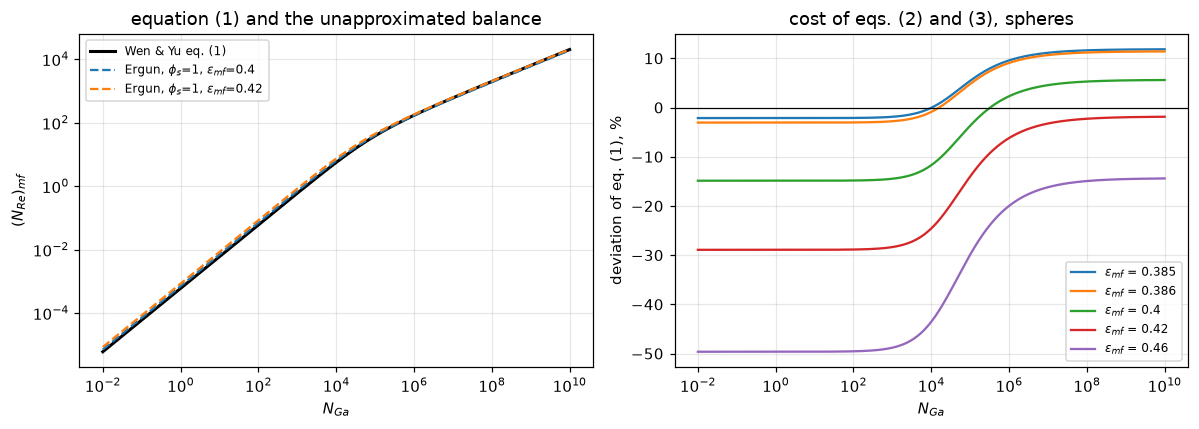

deviation of eq. (1) from the unapproximated Ergun balance, phi_s = 1; monotone in N_Ga for all five voidages
  eps_mf   viscous limit   turbulent limit    |viscous| > |turbulent|
   0.385           -2.1 %            +11.9 %                         no
   0.386           -3.1 %            +11.4 %                         no
   0.400          -14.9 %             +5.6 %                        yes
   0.420          -28.9 %             -1.8 %                        yes
   0.460          -49.6 %            -14.4 %                        yes

The grid ends (N_Ga = 1e-2 and 1e10) are not quite the limits: they differ by at most 8.6e-06 points (viscous) and 0.059 points (turbulent),
because the other term of eq. (1) is still there at 1e10: C1 / (N_Re)_mf is about 1e-3. The limits are used throughout.

At the eps_mf = 0.42 that Wen & Yu print for their own spherical data,
eq. (1) is 28.9 % LOW in the viscous limit and 1.8 % low in the turbulent limit.
The viscous limit is exact (zero deviation) a

In [10]:
N_Ga_grid = np.logspace(-2, 10, 600)
re_wy_grid = re_mf_wen_yu(N_Ga_grid)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
LIM = {}        # eps -> (viscous limit, turbulent limit), % deviation of eq. (1)
GRID_END = {}   # eps -> deviation at the two ends of the grid, %
for eps in EPS_QUOTED:
    ref = ergun_re_mf(N_Ga_grid, 1.0, eps)
    dev = 100 * (re_wy_grid - ref) / ref
    assert np.all(np.diff(dev) > 0) or np.all(np.diff(dev) < 0), f"deviation not monotone at eps = {eps}"
    LIM[eps] = limit_deviations(eps=eps)
    GRID_END[eps] = (dev[0], dev[-1])
    assert dev.min() >= min(LIM[eps]) - 1e-9 and dev.max() <= max(LIM[eps]) + 1e-9, "grid outside the limits"
    ax[1].semilogx(N_Ga_grid, dev, label=f"$\\epsilon_{{mf}}$ = {eps}")
ax[0].loglog(N_Ga_grid, re_wy_grid, "k", lw=2, label="Wen & Yu eq. (1)")
for eps in (0.40, 0.42):
    ax[0].loglog(N_Ga_grid, ergun_re_mf(N_Ga_grid, 1.0, eps), "--",
                 label=f"Ergun, $\\phi_s$=1, $\\epsilon_{{mf}}$={eps}")
ax[0].set_xlabel("$N_{Ga}$"); ax[0].set_ylabel("$(N_{Re})_{mf}$")
ax[0].set_title("equation (1) and the unapproximated balance"); ax[0].legend(fontsize=8)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xlabel("$N_{Ga}$"); ax[1].set_ylabel("deviation of eq. (1), %")
ax[1].set_title("cost of eqs. (2) and (3), spheres"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

print("deviation of eq. (1) from the unapproximated Ergun balance, phi_s = 1; monotone in N_Ga for all five voidages")
print(f"{'eps_mf':>8s} {'viscous limit':>15s} {'turbulent limit':>17s}   {'|viscous| > |turbulent|':>24s}")
for eps, (dv, dt) in LIM.items():
    print(f"{eps:8.3f} {dv:+14.1f} % {dt:+16.1f} %   {'yes' if abs(dv) > abs(dt) else 'no':>24s}")
gv = max(abs(GRID_END[e][0] - LIM[e][0]) for e in LIM)
gt = max(abs(GRID_END[e][1] - LIM[e][1]) for e in LIM)
print(f"\nThe grid ends (N_Ga = 1e-2 and 1e10) are not quite the limits: they differ by at most "
      f"{gv:.1e} points (viscous) and {gt:.3f} points (turbulent),")
print("because the other term of eq. (1) is still there at 1e10: C1 / (N_Re)_mf is about 1e-3. The limits are used throughout.")

# the words in the text below rest on these signs
assert LIM[0.42][0] < 0 and LIM[0.42][1] < 0 and LIM[0.385][1] > 0 and LIM[0.386][1] > 0
assert LIM[0.385][0] < 0 and LIM[0.386][0] < 0
DEV_VISC_042, DEV_TURB_042 = LIM[0.42]
DEV_VISC_040 = LIM[0.40][0]
claims.value("dev_vs_exact_ergun_viscous_eps042_pct", DEV_VISC_042)
claims.value("dev_vs_exact_ergun_turbulent_eps042_pct", DEV_TURB_042)
claims.value("dev_vs_exact_ergun_viscous_eps040_pct", DEV_VISC_040)
DIFF_WORSE = np.array([abs(LIM[e][0]) - abs(LIM[e][1]) for e in EPS_QUOTED])
N_VISC_WORSE = claims.count("voidages_with_viscous_end_worse", DIFF_WORSE, 0.0, min_margin=1.0,
                            note="of the five voidages, margin in percentage points")
def flip_voidage(**kw):
    """The voidage at which the viscous and turbulent deviations are equal in size, by ``find_roots``
    on the bracket between the two voidages that make one of them zero (for a sphere, those of eqs. (2)
    and (3)); exactly one root on each, or it raises."""
    zv = one_root(lambda e: limit_deviations(eps=e, **kw)[0], 0.3, 0.6, n_scan=300, xtol=1e-12)
    zt = one_root(lambda e: limit_deviations(eps=e, **kw)[1], 0.3, 0.6, n_scan=300, xtol=1e-12)

    def f(e):
        v, t = limit_deviations(eps=e, **kw)
        return abs(v) - abs(t)
    return one_root(f, min(zv, zt), max(zv, zt), n_scan=200, xtol=1e-12)


EPS_FLIP = flip_voidage()
claims.value("viscous_turbulent_flip_eps", EPS_FLIP)
# the sign changes: the viscous limit crosses zero at the voidage eq. (2) forces on a sphere, the turbulent
# limit at the one eq. (3) forces; between them eq. (1) is low at one end and high at the other
print(f"\nAt the eps_mf = 0.42 that Wen & Yu print for their own spherical data,")
print(f"eq. (1) is {abs(DEV_VISC_042):.1f} % LOW in the viscous limit and {abs(DEV_TURB_042):.1f} % "
      f"{'low' if DEV_TURB_042 < 0 else 'high'} in the turbulent limit.")
print(f"The viscous limit is exact (zero deviation) at eps_mf = {EPS_FROM_2:.4f}, the turbulent limit at "
      f"{EPS_FROM_3:.4f} (the voidages eqs. (2) and (3) force on a sphere):")
print(f"between them eq. (1) is low at the viscous end and high at the turbulent end, and the viscous end is the worse one in "
      f"{N_VISC_WORSE} of the {len(EPS_QUOTED)} voidages above.")
print(f"The two ends are equally far from the balance at eps_mf = {EPS_FLIP:.3f}; above it the viscous end is the worse one, below it the turbulent end.")

In [11]:
display(Markdown(fill(r"""The asymmetry is the second substantive result, and it is large, **but which end is
worse depends on the voidage**, so it is not a statement about the correlation alone.

The two approximations do not degrade the correlation uniformly. In the small-particle limit
equation (1) reduces to $(N_{Re})_{mf} = N_{Ga}/(k_1\!\times\!11) = N_{Ga}/1650$,
carrying the full error of equation (2). In the large-particle limit it reduces
to $(N_{Re})_{mf} = \sqrt{N_{Ga}/(k_2\!\times\!14)} = \sqrt{N_{Ga}/24.5}$, and
the square root halves whatever error equation (3) carries. At the $\epsilon_{mf} = 0.42$ Wen
and Yu print for their own data, equation (2)'s group is far from its target (the viscous
end is @@v42@@ % low) while equation (3)'s is close (the turbulent end is @@t42@@ % low). At
0.385 and 0.386 the order reverses: the viscous end is only @@v385@@ and @@v386@@ % low and the
turbulent end is @@t385@@ and @@t386@@ % **high**. Of the five voidages the paper quotes, the viscous end
is the worse one at @@nv@@, the turbulent end at @@nt@@.

This matters for reading the rest of the page. Every measurement available here
is at the viscous end, so the deviations reported below test that end and say
nothing about the other. Whether they are a lower or an upper bound on the
correlation's error over its whole range depends on a voidage the data do not fix.

### 4. Is any of this the Ergun constants' fault?

`A1.1` refitted Ergun's two constants to 244 markers digitised out of his own
Figure 7 and got @@k1r@@ and @@k2r@@ against his printed 150 and 1.75. Pushing that
uncertainty through the same derivation separates the two candidate explanations
for the deviations above.
""", v42=f"{abs(DEV_VISC_042):.1f}", t42=f"{abs(DEV_TURB_042):.1f}", v385=f"{abs(LIM[0.385][0]):.1f}",
    v386=f"{abs(LIM[0.386][0]):.1f}", t385=f"{LIM[0.385][1]:.1f}", t386=f"{LIM[0.386][1]:.1f}",
    nv=N_VISC_WORSE, nt=len(EPS_QUOTED) - N_VISC_WORSE, k1r=f"{K1_REFIT:.1f}", k2r=f"{K2_REFIT:.3f}")))

The asymmetry is the second substantive result, and it is large, **but which end is
worse depends on the voidage**, so it is not a statement about the correlation alone.

The two approximations do not degrade the correlation uniformly. In the small-particle limit
equation (1) reduces to $(N_{Re})_{mf} = N_{Ga}/(k_1\!\times\!11) = N_{Ga}/1650$,
carrying the full error of equation (2). In the large-particle limit it reduces
to $(N_{Re})_{mf} = \sqrt{N_{Ga}/(k_2\!\times\!14)} = \sqrt{N_{Ga}/24.5}$, and
the square root halves whatever error equation (3) carries. At the $\epsilon_{mf} = 0.42$ Wen
and Yu print for their own data, equation (2)'s group is far from its target (the viscous
end is 28.9 % low) while equation (3)'s is close (the turbulent end is 1.8 % low). At
0.385 and 0.386 the order reverses: the viscous end is only 2.1 and 3.1 % low and the
turbulent end is 11.9 and 11.4 % **high**. Of the five voidages the paper quotes, the viscous end
is the worse one at 3, the turbulent end at 2.

This matters for reading the rest of the page. Every measurement available here
is at the viscous end, so the deviations reported below test that end and say
nothing about the other. Whether they are a lower or an upper bound on the
correlation's error over its whole range depends on a voidage the data do not fix.

### 4. Is any of this the Ergun constants' fault?

`A1.1` refitted Ergun's two constants to 244 markers digitised out of his own
Figure 7 and got 151.9 and 1.697 against his printed 150 and 1.75. Pushing that
uncertainty through the same derivation separates the two candidate explanations
for the deviations above.


In [12]:
def error_budget(refit=(K1_REFIT, K2_REFIT), eps=0.42, printed=(C1_PRINT, C2_PRINT)):
    """The two costs compared limit by limit: eqs. (2), (3) at voidage ``eps`` against the exact balance,
    and the refit of Ergun's constants ``refit`` pushed through the same derivation.

    The refit is measured against the UNROUNDED recovered pair, so that the rounding of the printed
    33.7 and 0.0408 is not folded into a statement about Ergun's constants.
    """
    pair = wen_yu_constants(*refit)
    erg_v, erg_t = limit_ratios(pair, wen_yu_constants())
    void_v, void_t = limit_deviations(eps=eps)
    vs_printed = limit_ratios(pair, printed)
    return dict(
        ergun_constant_share_viscous_pct=erg_v, ergun_constant_share_turbulent_pct=erg_t,
        voidage_over_ergun_ratio_viscous=abs(void_v) / abs(erg_v),
        voidage_over_ergun_ratio_turbulent=abs(void_t) / abs(erg_t),
        ergun_constant_share_pct=max(abs(erg_v), abs(erg_t)),
        voidage_approximation_share_pct=abs(void_v),
        voidage_over_ergun_ratio_viscous_vs_printed=abs(void_v) / abs(vs_printed[0]),
        voidage_over_ergun_ratio_turbulent_vs_printed=abs(void_t) / abs(vs_printed[1]),
        _vs_printed=vs_printed, _void=(void_v, void_t), _pair=pair)


EB = error_budget()
C1_rf, C2_rf = EB["_pair"]
ERG_VISC, ERG_TURB = EB["ergun_constant_share_viscous_pct"], EB["ergun_constant_share_turbulent_pct"]
VOID_VISC, VOID_TURB = EB["_void"]
RATIO_VISC, RATIO_TURB = EB["voidage_over_ergun_ratio_viscous"], EB["voidage_over_ergun_ratio_turbulent"]
ERGUN_SHARE, VOIDAGE_SHARE = EB["ergun_constant_share_pct"], EB["voidage_approximation_share_pct"]
for name, v in EB.items():
    if not name.startswith("_"):
        claims.value(name, v)

print("A1.1's refit of Ergun's own constants, pushed through the same derivation")
print(f"  k1: {K1_ERGUN:g} -> {K1_REFIT:.5g}   ({100*(K1_REFIT-K1_ERGUN)/K1_ERGUN:+.2f} %)")
print(f"  k2: {K2_ERGUN:g} -> {K2_REFIT:.5g}  ({100*(K2_REFIT-K2_ERGUN)/K2_ERGUN:+.2f} %)")
print(f"  C1: {C1_rec:.4f} -> {C1_rf:.4f}   ({100*(C1_rf-C1_rec)/C1_rec:+.2f} %)")
print(f"  C2: {C2_rec:.6f} -> {C2_rf:.6f} ({100*(C2_rf-C2_rec)/C2_rec:+.2f} %)")
print(f"\n  effect on the PREDICTION, in the two limits: {ERG_VISC:+.2f} % (viscous), {ERG_TURB:+.2f} % (turbulent)")
print("  (measured against the recovered pair, not the printed 33.7/0.0408, so the")
print("   rounding of the printed constants is not folded into the comparison.)")

# --- LIKE FOR LIKE. Both costs vary across the Reynolds range, in OPPOSITE ---
# --- directions (at eps = 0.42), so they must be compared at the same limit ---
print(f"\n{'limit':>10s} {'eqs. (2),(3) at eps=0.42':>26s} {'Ergun constants (A1.1 refit)':>30s} {'ratio':>8s}")
print(f"{'viscous':>10s} {VOID_VISC:+25.2f} % {ERG_VISC:+29.2f} % {RATIO_VISC:7.1f}x")
print(f"{'turbulent':>10s} {VOID_TURB:+25.2f} % {ERG_TURB:+29.2f} % {RATIO_TURB:7.2f}x")
print(f"\nThe two costs are NOT one ratio. At eps = 0.42 the voidage approximation outweighs the")
print(f"friction-law uncertainty by {RATIO_VISC:.1f}x in the VISCOUS limit and by only "
      f"{RATIO_TURB:.2f}x in the")
print(f"TURBULENT one, where they are the same size ({abs(VOID_TURB):.1f} % against "
      f"{abs(ERG_TURB):.1f} %). Quoting the worst")
print(f"voidage cost ({VOIDAGE_SHARE:.1f} %, viscous) against the worst Ergun cost "
      f"({ERGUN_SHARE:.2f} %, turbulent)")
print(f"would give {VOIDAGE_SHARE/ERGUN_SHARE:.0f}x, but that is two different limits and is not a")
print("like-for-like comparison. At the coarse end, where eps = 0.42 puts the approximation at its")
print("best, refitting Ergun's constants matters as much as the approximation does.")
print(f"\n(The two limit-wise ratios are quoted against the RECOVERED pair. Against the")
print(f" printed 33.7/0.0408 instead they are {EB['voidage_over_ergun_ratio_viscous_vs_printed']:.0f}x viscous and "
      f"{EB['voidage_over_ergun_ratio_turbulent_vs_printed']:.2f}x turbulent: the printed")
print(f" constants are rounded to three figures, and quoting against them folds Wen &")
print(f" Yu's rounding into a comparison that is supposed to be about Ergun's constants.")
print(f" Either way the answer is the same: a large factor in the viscous limit, a factor near one in the")
print(f" turbulent one, and NOT one number.)")
print("\nNote the constants move more than the prediction does. C1 and C2 are not")
print("independently identifiable from a Re: only 1/(k1 g2) and 1/(k2 g3) are, and")
print("a shift in k1 and k2 moves C1 and C2 partly in the same direction.")

A1.1's refit of Ergun's own constants, pushed through the same derivation
  k1: 150 -> 151.94   (+1.29 %)
  k2: 1.75 -> 1.6967  (-3.05 %)
  C1: 33.6735 -> 35.1796   (+4.47 %)
  C2: 0.040816 -> 0.042098 (+3.14 %)

  effect on the PREDICTION, in the two limits: -1.27 % (viscous), +1.56 % (turbulent)
  (measured against the recovered pair, not the printed 33.7/0.0408, so the
   rounding of the printed constants is not folded into the comparison.)

     limit   eqs. (2),(3) at eps=0.42   Ergun constants (A1.1 refit)    ratio
   viscous                    -28.92 %                         -1.27 %    22.7x
 turbulent                     -1.83 %                         +1.56 %    1.17x

The two costs are NOT one ratio. At eps = 0.42 the voidage approximation outweighs the
friction-law uncertainty by 22.7x in the VISCOUS limit and by only 1.17x in the
TURBULENT one, where they are the same size (1.8 % against 1.6 %). Quoting the worst
voidage cost (28.9 %, viscous) against the worst Ergun cost 

## Validation

Four checks, in the order of `docs/agent-brief.md`: an internal identity the
paper must satisfy, a second internal identity inside its own table, a
comparison against measurement, and a deliberate-break table for each. Nothing
here is a figure trace.

### Check 1: the re-derivation, and whether it could have failed

The recovery of 33.7 and 0.0408 to a tenth of a per cent is only evidence if
plausible alternatives give something else. Each row below changes one input to
the derivation and re-reads the constants; the rows that change a voidage group
also move the effective particle of Result 2.

In [13]:
def derivation(k1=K1_ERGUN, k2=K2_ERGUN, g2=G2_PRINT, g3=G3_PRINT):
    """Every claim of Results 1 and 2 as a function of the inputs of the derivation."""
    c1, c2 = wen_yu_constants(k1, k2, g2, g3)
    out = dict(C1_recovered=c1, C2_recovered=c2,
               C1_deviation_pct=100 * (c1 - C1_PRINT) / C1_PRINT,
               C2_deviation_pct=100 * (c2 - C2_PRINT) / C2_PRINT)
    out.update(particle(g2, g3))
    try:
        out.update(sphere_voidage(g2, g3))
    except ValueError:
        pass
    return out


variants = [
    ("none: as built (Ergun 150/1.75, eqs 2 and 3)", dict()),
    ("eqs. (2) and (3) swapped",                      dict(g2=G3_PRINT, g3=G2_PRINT)),
    ("eq. (2) mis-read as 1.1",                       dict(g2=1.1)),
    ("eq. (3) mis-read as 4",                         dict(g3=4.0)),
    ("Kozeny-Carman k1 = 180 instead of 150",         dict(k1=K1_CARMAN)),
    ("Eisfeld-Schnitzlein infinite bed, 154 / 1.32",  dict(k1=K1_EISFELD, k2=K2_EISFELD)),
]
refit_row = ("(not a defect) A1.1 refit of Ergun's constants", dict(k1=K1_REFIT, k2=K2_REFIT))
extra_row = ("eq. (2) mis-read as 12", dict(g2=12.0))
print(f"{'injected defect':47s} {'C1':>9s} {'dev %':>8s} {'C2':>9s} {'dev %':>8s}   {'eps_mf, phi_s of eqs (2)+(3)':>30s}")
brk1 = []
for name, kw in variants + [refit_row]:
    got = derivation(**kw)
    brk1.append((name, got))
    eff = (f"{got['implied_eps_mf']:.4f}, {got['implied_phi_s']:.4f}" if np.isfinite(got["implied_eps_mf"])
           else "no admissible particle")
    print(f"{name:47s} {got['C1_recovered']:9.3f} {got['C1_deviation_pct']:+8.2f} "
          f"{got['C2_recovered']:9.6f} {got['C2_deviation_pct']:+8.2f}   {eff:>30s}")
    if name != "none: as built (Ergun 150/1.75, eqs 2 and 3)" and not name.startswith("(not a defect)"):
        brk_all(name, got)
wrong = [g for n, g in brk1[1:-1]]
WORST_ALT = min(max(abs(g["C1_deviation_pct"]), abs(g["C2_deviation_pct"])) for g in wrong)
BEST_READ = max(abs(d1), abs(d2))
REFIT_MOVE = max(abs(brk1[-1][1]["C1_deviation_pct"]), abs(brk1[-1][1]["C2_deviation_pct"]))
print(f"\nSmallest disturbance any of the {len(wrong)} wrong readings produces: {WORST_ALT:.2f} %,")
print(f"against {BEST_READ:.3f} % for the reading actually used, a factor "
      f"{WORST_ALT/BEST_READ:.0f}.")
print(f"\nRESOLVING POWER. The last row is not a defect: it is A1.1's refit of Ergun's")
print(f"own constants to his own figure, and it moves the recovered constants by "
      f"{REFIT_MOVE:.1f} %.")
print(f"So this check resolves 150 from 180 or from 154; it does NOT resolve 150 from")
print(f"{K1_REFIT:.1f}. It identifies the FORM and the rounded pair, not the third digit.")
got12 = derivation(**extra_row[1])
brk_all(extra_row[0], got12)
print(f"\nOne more row, for the effective particle of Result 2: {extra_row[0]} moves it to "
      f"eps_mf = {got12['implied_eps_mf']:.4f}, phi_s = {got12['implied_phi_s']:.4f} "
      f"(C1 {got12['C1_deviation_pct']:+.1f} %).")
print("\nWHAT THIS CHECK CANNOT DO:")
print("  * It cannot tell whether Ergun's 150 and 1.75 are RIGHT. It identifies which")
print("    friction-law constants Wen & Yu used, given that they used the Ergun form.")
print("  * It cannot separate a compensating pair of errors: k1 = 300 with eq.(2) = 5.5")
print(f"    gives C1 = {wen_yu_constants(300.0, K2_ERGUN, 5.5, G3_PRINT)[0]:.3f} and "
      f"C2 = {wen_yu_constants(300.0, K2_ERGUN, 5.5, G3_PRINT)[1]:.6f}: both exact.")
print("    Only the products k1*g2 and k2*g3 are identifiable.")

injected defect                                        C1    dev %        C2    dev %     eps_mf, phi_s of eqs (2)+(3)
none: as built (Ergun 150/1.75, eqs 2 and 3)       33.673    -0.08  0.040816    +0.04                   0.4744, 0.6689
eqs. (2) and (3) swapped                           54.545   +61.86  0.051948   +27.32           no admissible particle
eq. (2) mis-read as 1.1                             3.367   -90.01  0.040816    +0.04           no admissible particle
eq. (3) mis-read as 4                             117.857  +249.72  0.142857  +250.14           no admissible particle
Kozeny-Carman k1 = 180 instead of 150              40.408   +19.91  0.040816    +0.04                   0.4744, 0.6689
Eisfeld-Schnitzlein infinite bed, 154 / 1.32       45.792   +35.88  0.054064   +32.51                   0.4744, 0.6689
(not a defect) A1.1 refit of Ergun's constants     35.180    +4.39  0.042098    +3.18                   0.4744, 0.6689

Smallest disturbance any of the 5 wrong reading

In [14]:
# Break rows for Results 3 and 4: the claims they register are moved by the reference balance
# (voidage, friction constants, sphericity), by eq. (1)'s constants and by the refit used.
def cost_claims(**kw):
    """The Result 3 claims for the defect ``kw`` (arguments of ``limit_deviations``)."""
    v42, t42 = limit_deviations(eps=0.42, **kw)
    v40, _ = limit_deviations(eps=0.40, **kw)
    count = int(sum(abs(limit_deviations(eps=e, **kw)[0]) > abs(limit_deviations(eps=e, **kw)[1])
                    for e in EPS_QUOTED))
    out = dict(dev_vs_exact_ergun_viscous_eps042_pct=v42, dev_vs_exact_ergun_turbulent_eps042_pct=t42,
               dev_vs_exact_ergun_viscous_eps040_pct=v40, voidages_with_viscous_end_worse=count)
    try:
        out["viscous_turbulent_flip_eps"] = flip_voidage(**kw)
    except ValueError:      # the defect leaves no flip on the bracket: no value to report
        pass
    return out


A1_PANEL = (_a11["k1_panel_present_investigation"], _a11["k2_panel_present_investigation"])
for row, kw in [("C1 and C2 swapped in eq. (1)", dict(C1=C2_PRINT, C2=C1_PRINT)),
                ("Kozeny-Carman k1 = 180 in the reference balance", dict(k1=K1_CARMAN)),
                ("Eisfeld-Schnitzlein k2 (1.32) in the reference balance", dict(k2=K2_EISFELD)),
                ("Ergun k2 = 3.5 (twice the printed 1.75) in the reference balance", dict(k2=3.5)),
                ("reference balance for phi_s = 0.9 instead of a sphere", dict(phi_s=0.9))]:
    brk_all(row, cost_claims(**kw))
# a shifted voidage: every voidage of the table read 0.05 high
_sh = {e: limit_deviations(eps=e + 0.05) for e in EPS_QUOTED}
brk_all("every voidage of the table read 0.05 high",
        dict(dev_vs_exact_ergun_viscous_eps042_pct=_sh[0.40][0], dev_vs_exact_ergun_turbulent_eps042_pct=_sh[0.40][1],
             dev_vs_exact_ergun_viscous_eps040_pct=_sh[0.385][0],
             voidages_with_viscous_end_worse=int(sum(abs(v) > abs(t) for v, t in _sh.values()))))
for row, kw in [("the refit of the present-investigation panel alone used (k1 = 146.6, k2 = 1.884)", dict(refit=A1_PANEL)),
                ("refit constants swapped (k1 and k2 exchanged)", dict(refit=(K2_REFIT, K1_REFIT))),
                ("Kozeny-Carman k1 = 180 as the refit", dict(refit=(K1_CARMAN, K2_REFIT))),
                ("voidage of the approximation read 0.40 instead of 0.42", dict(eps=0.40))]:
    brk_all(row, {k: v for k, v in error_budget(**kw).items() if not k.startswith("_")})

### Check 2: Wen and Yu's Table 1 against itself

A standard deviation over a pooled population is the root-mean-square of its
subgroup values weighted by their counts. Table 1 prints three subgroups, their
point counts, and an overall, so it can be asked whether the overall is the
pooling of the rows. Footnote * states the Narsimhan basis is 267 points, and the
three counts sum to exactly that, so for that column the question is
well posed. Footnote † says the Equation (1) overall is over all 284, so for
*that* column it is not, and the check reports the discrepancy rather than
excusing it.

In [15]:
N_NAR, N_EQ1 = 267, 284   # footnotes * and +


def pool(w, v):
    """Count-weighted root-mean-square of subgroup standard deviations ``v`` with counts ``w``."""
    w, v = np.asarray(w, float), np.asarray(v, float)
    return float(np.sqrt((w * v**2).sum() / w.sum()))


def table1(df=None, counts=None, keep=(0, 1, 2)):
    """Table 1's pooling identity: the claims for a (possibly mis-transcribed) table.

    ``counts`` replaces the printed row counts, ``keep`` selects the rows pooled.
    """
    df = wy if df is None else df
    rows = df[df.row < 4].iloc[list(keep)]
    n = rows.n_points.to_numpy(float) if counts is None else np.asarray(counts, float)[list(keep)]
    nar, eq1 = rows.std_dev_narsimhan_pct.to_numpy(float), rows.std_dev_eq1_pct.to_numpy(float)
    over = df[df.row == 4].iloc[0]
    p_nar, p_eq1 = pool(n, nar), pool(n, eq1)
    need = N_EQ1 * over.std_dev_eq1_pct**2        # sum(n v^2) the printed overall needs
    reach = (N_EQ1 * eq1.min()**2, N_EQ1 * eq1.max()**2)
    return dict(
        table1_narsimhan_pooled=p_nar, table1_narsimhan_printed=float(over.std_dev_narsimhan_pct),
        table1_narsimhan_closure_pct=100 * (p_nar - over.std_dev_narsimhan_pct) / over.std_dev_narsimhan_pct,
        table1_eq1_pooled=p_eq1, table1_eq1_printed=float(over.std_dev_eq1_pct),
        table1_eq1_closure_pct=100 * (p_eq1 - over.std_dev_eq1_pct) / over.std_dev_eq1_pct,
        table1_eq1_extra_points_variance=(need - N_NAR * p_eq1**2) / (N_EQ1 - N_NAR),
        table1_eq1_printed_reachable=bool(reach[0] <= need <= reach[1]),
        _need=need, _reach=reach, _n=n)


T1 = table1()
n_rows = wy[wy.row < 4].n_points.to_numpy(float)
for name, v in T1.items():
    if name.startswith("_"):
        continue
    if name in ("table1_narsimhan_printed", "table1_eq1_printed", "table1_eq1_printed_reachable"):
        claims.exact(name, v)
    else:
        claims.value(name, v)
printed_nar, printed_eq1 = T1["table1_narsimhan_printed"], T1["table1_eq1_printed"]
print(f"row counts {n_rows.astype(int)} sum to {int(n_rows.sum())}; footnote * gives {N_NAR} for Narsimhan")
print(f"\nNarsimhan  : rows pool to {T1['table1_narsimhan_pooled']:.3f} %  vs printed {printed_nar:g} %"
      f"   ({T1['table1_narsimhan_closure_pct']:+.2f} %)")
print(f"Equation(1): rows pool to {T1['table1_eq1_pooled']:.3f} %  vs printed {printed_eq1:g} %"
      f"   ({T1['table1_eq1_closure_pct']:+.2f} %)")
print(f"\nThe Narsimhan column closes to {abs(T1['table1_narsimhan_closure_pct']):.1f} % on a printed integer,")
print("which tests all four of its numbers and the three point counts at once.")
print(f"\nThe Equation (1) column does NOT close ON THE PRINTED COUNTS, and on that")
print(f"basis cannot be made to: adding the")
print(f"{N_EQ1-N_NAR} extra points would have to REDUCE a pooled rms from {T1['table1_eq1_pooled']:.2f} to "
      f"{printed_eq1:g},")
print("which is impossible for any deviation those points could carry:")
print(f"  required: ({N_EQ1} x {printed_eq1:g}^2 - {N_NAR} x {T1['table1_eq1_pooled']:.3f}^2) / "
      f"{N_EQ1-N_NAR} = {T1['table1_eq1_extra_points_variance']:.0f}, a NEGATIVE variance.")
print("So the Equation (1) row entries are computed on a different split of the 284")
print("than the printed counts, which the footnotes imply but do not spell out.")
print("This page reports that; it does not repair it.")
print("\nSTATED PRECISELY, because the strong version is not proved: what cannot")
print("close is the printed row COUNTS as the basis of the Equation (1) column.")
print(f"With an unconstrained split of the {N_EQ1} among the three classes the printed {printed_eq1:g}")
print(f"IS reachable: it needs sum(n v^2) = {T1['_need']:.0f}, and with these three row")
print(f"values the achievable range is [{T1['_reach'][0]:.0f}, {T1['_reach'][1]:.0f}].")
print("The column is therefore not shown to be impossible; the stated basis is.")
print("The result is also robust to what 'standard deviation' means: read about the")
print("group means instead of about zero, pooling gives sum n (s^2 + (m-M)^2) / N,")
print("which is >= the value used here, so the contradiction only widens.")


def perturbed(df, col, value, row):
    """Copy of ``df`` with one cell replaced (a mis-transcription)."""
    out = df.copy()
    out.loc[out.index[row], col] = value
    return out


NAR, EQ1 = "std_dev_narsimhan_pct", "std_dev_eq1_pct"
t1_defects = [
    ("135.3 mis-read as 35.3",                         table1(perturbed(wy, NAR, 35.3, 2))),
    ("43.4 and 38.6 swapped",                          table1(perturbed(perturbed(wy, NAR, 38.6, 0), NAR, 43.4, 1))),
    ("equal weights instead of counts",                table1(counts=np.ones(3))),
    ("the 9-point row dropped",                        table1(keep=(0, 1))),
    ("count 203 mis-read as 20",                       table1(counts=[55, 20, 9])),
    ("Equation (1) entry 21.3 mis-read as 71.3",       table1(perturbed(wy, EQ1, 71.3, 2))),
    ("overall Narsimhan 46 mis-read as 40",            table1(perturbed(wy, NAR, 40.0, 3))),
    ("overall Equation (1) 34 mis-read as 38",         table1(perturbed(wy, EQ1, 38.0, 3))),
]
print("\n--- break table: does the pooling identity move? (Narsimhan rows pool to "
      f"{T1['table1_narsimhan_pooled']:.2f} % against a printed {printed_nar:g}) ---")
for row, got in t1_defects:
    brk_all(row, {k: v for k, v in got.items() if not k.startswith("_")})
    print(f"  {row:45s} Narsimhan pooled = {got['table1_narsimhan_pooled']:7.2f} %   "
          f"Eq. (1) pooled = {got['table1_eq1_pooled']:7.2f} %   reachable: {got['table1_eq1_printed_reachable']}")

row counts [ 55 203   9] sum to 267; footnote * gives 267 for Narsimhan

Narsimhan  : rows pool to 46.237 %  vs printed 46 %   (+0.52 %)
Equation(1): rows pool to 36.465 %  vs printed 34 %   (+7.25 %)

The Narsimhan column closes to 0.5 % on a printed integer,
which tests all four of its numbers and the three point counts at once.

The Equation (1) column does NOT close ON THE PRINTED COUNTS, and on that
basis cannot be made to: adding the
17 extra points would have to REDUCE a pooled rms from 36.47 to 34,
which is impossible for any deviation those points could carry:
  required: (284 x 34^2 - 267 x 36.465^2) / 17 = -1572, a NEGATIVE variance.
So the Equation (1) row entries are computed on a different split of the 284
than the printed counts, which the footnotes imply but do not spell out.
This page reports that; it does not repair it.

STATED PRECISELY, because the strong version is not proved: what cannot
close is the printed row COUNTS as the basis of the Equation (1) column.
With

### Check 3: against 21 measured minimum fluidisation velocities

This is the only check on the page that involves a measurement. Equation (1) is
evaluated on Geldart's printed sizes, densities, $\mu$ and $g$, and compared with
his measured $U_0$. Nothing is fitted, and Geldart's data postdates the
correlation by seven years.

In [16]:
def measured(df=None, *, d_to_cm=1e-4, mu=MU_CGS, g=G_CGS, rho_f=RHOF_CGS, rho_f_in_drho=True,
             u_col="U_0", u_shift=0, wy_fn=None, wy_c=(C1_PRINT, C2_PRINT), phi_s=1.0,
             dr_const=DR_CONST, drop_blank=True, strict=True):
    """Every claim of the measured comparison, for the data ``df`` and the inputs given.

    The keyword arguments are the places a defect can be injected: the unit of the size
    column, the gas properties, which velocity column is read, a shifted column, the correlation
    used in place of eq. (1), its constants, the assumed sphericity (``d_p = d_sv / phi_s``), the
    Davies-Richardson constant, and whether the blank row is dropped. With ``strict=False`` a
    root-finding step that finds no unique root reports NaN instead of raising (a defective
    run may have none).

    Returns ``(claim values, arrays)``.
    """
    df = gd if df is None else df
    m = df.dropna(subset=["U_0"]).copy() if drop_blank else df.copy()
    d = m.d_sv_um.to_numpy(float) * d_to_cm                    # d_sv, cm
    drho = m.rho_s.to_numpy(float) - (rho_f if rho_f_in_drho else 0.0)
    U = np.roll(m[u_col].to_numpy(float), u_shift)
    dia = (m.powder == "Diakon").to_numpy()
    dp = d / phi_s                                             # volume-equivalent diameter
    Ga = dp**3 * rho_f * drho * g / mu**2
    Re = re_mf_wen_yu(Ga, *wy_c) if wy_fn is None else wy_fn(Ga)
    u_wy = u_mf_from_re(Re, dp, mu, rho_f)
    dev = 100 * (u_wy - U) / U
    u_dr = dr_const * g * d**2 * drho / mu                      # Geldart's eq. (3), in d_sv
    ddr = 100 * (u_dr - U) / U
    # the viscous contribution to eq. (1), and the share of the inertial term
    inert = 100 * np.abs(Re - Ga / (2 * wy_c[0] / wy_c[1])) / Re
    # the exact Ergun balance is written in d_sv: it is phi_s-free
    Ga_sv = d**3 * rho_f * drho * g / mu**2
    rows = np.flatnonzero(dia)
    d_d, drho_d, U_d, Ga_d = d[dia], drho[dia], U[dia], Ga_sv[dia]
    eps_MB = m.eps_MB.to_numpy(float)[dia]
    H = m.H_MB_over_H_0.to_numpy(float)[dia]
    eps_0 = 1.0 - (1.0 - eps_MB) * H

    def exact_bias(eps):
        u = u_mf_from_re(ergun_re_mf(Ga_d, 1.0, eps), d_d, mu, rho_f)
        return 100 * (u - U_d) / U_d

    dev_042, dev_MB, dev_e0 = exact_bias(0.42), exact_bias(eps_MB), exact_bias(eps_0)

    def diakon_bias(p):
        """Mean deviation of eq. (1) on the Diakon rows if their sphericity were ``p``."""
        dpp = d_d / p
        Gp = dpp**3 * rho_f * drho_d * g / mu**2
        Rp = re_mf_wen_yu(Gp, *wy_c) if wy_fn is None else wy_fn(Gp)
        return float(np.mean(100 * (u_mf_from_re(Rp, dpp, mu, rho_f) - U_d) / U_d))

    Re_d = d_d * rho_f * U_d / mu                               # the measured Reynolds numbers
    try:
        eps_row = np.array([one_root(lambda e, A=A, R=R: ergun_re_mf(A, 1.0, e) - R, EPS_FCC, 1.0, xtol=1e-12)
                            for A, R in zip(Ga_d, Re_d)])
    except ValueError:
        if strict:
            raise
        eps_row = np.full(len(d_d), np.nan)
    try:
        phi_zero = one_root(diakon_bias, PHI_RANGE[0], PHI_RANGE[1], xtol=1e-10)
    except ValueError:
        if strict:
            raise
        phi_zero = np.nan
    K_row = d_d**2 * drho_d * g / (mu * U_d)                    # the viscous constant each row demands
    rho_sp, p_sp = spearmanr(np.log(d_d), np.log(K_row))
    u_ref = d_d**2 * drho_d * g / (np.median(K_row) * mu)       # one-parameter d^2 law refitted to these rows
    out = dict(
        measured_rows=len(m),
        wenyu_bias_all_pct=dev.mean(), wenyu_mad_all_pct=np.abs(dev).mean(),
        wenyu_rms_all_pct=np.sqrt((dev**2).mean()),
        wenyu_sd_about_mean_all_pct=np.sqrt((dev**2).mean() - dev.mean()**2),
        wenyu_bias_diakon_pct=dev[dia].mean(), wenyu_mad_diakon_pct=np.abs(dev[dia]).mean(),
        wenyu_rms_diakon_pct=np.sqrt((dev[dia]**2).mean()),
        wenyu_dev_diakon_min_pct=dev[dia].min(), wenyu_dev_diakon_max_pct=dev[dia].max(),
        davies_richardson_bias_diakon_pct=ddr[dia].mean(), davies_richardson_mad_diakon_pct=np.abs(ddr[dia]).mean(),
        refit_one_parameter_mad_diakon_pct=np.abs(100 * (u_ref - U_d) / U_d).mean(),
        inverted_eps_mf_median_diakon=np.median(eps_row),
        inverted_viscous_constant_median_diakon=np.median(K_row),
        residual_size_rank_correlation=rho_sp, residual_size_rank_pvalue=p_sp,
        demanded_constant_decreases=int(np.sum(np.diff(K_row) < 0)),
        max_inertial_share_on_measured_rows_pct=inert.max(),
        max_measured_re_mf=Re.max(),
        wenyu_mad_fresh_pct=np.abs(dev[(m.powder == "Fresh catalyst").to_numpy()]).mean(),
        wenyu_mad_spent_pct=np.abs(dev[(m.powder == "Spent catalyst").to_numpy()]).mean(),
        constant_mean_velocity_mad_diakon_pct=np.abs(100 * (U_d.mean() - U_d) / U_d).mean(),
        eq1_error_surviving_refit_pct=100 * np.abs(100 * (u_ref - U_d) / U_d).mean() / np.abs(dev[dia]).mean(),
        exact_ergun_bias_diakon_eps042_pct=dev_042.mean(),
        exact_ergun_bias_diakon_at_reported_eps_MB_pct=dev_MB.mean(),
        exact_ergun_bias_diakon_at_settled_eps_0_pct=dev_e0.mean(),
        diakon_bias_at_phi_s_095_pct=diakon_bias(0.95), diakon_bias_at_phi_s_090_pct=diakon_bias(0.90),
        phi_s_that_erases_diakon_bias=phi_zero,
        # the same two derived quantities A1.7 computes and commits (relative gap)
        a17_eq3_constant_ratio_gap=max(abs(1 / (dr_const * K_row.max()) / _A17["eq3_K0eff_ratio_min_diakon"] - 1),
                                       abs(1 / (dr_const * K_row.min()) / _A17["eq3_K0eff_ratio_max_diakon"] - 1)))
    aux = dict(m=m, dev=dev, ddr=ddr, dia=dia, d=d, drho=drho, U=U, Ga=Ga, Re=Re, u_wy=u_wy, u_dr=u_dr,
               inert=inert, d_d=d_d, drho_d=drho_d, U_d=U_d, Ga_d=Ga_d, eps_MB=eps_MB, H=H, eps_0=eps_0,
               dev_042=dev_042, dev_MB=dev_MB, dev_e0=dev_e0, eps_row=eps_row, K_row=K_row,
               diakon_bias=diakon_bias, phi_zero=phi_zero)
    return out, aux


def no_inference(df=None, h_tol=1e-5, u_tol=1e-5):
    """The Diakon rows on which Geldart prints U_MB = U_0 and H_MB/H_0 = 1.000, so that
    eps_mf = eps_MB = eps_0 as printed. ``h_tol`` and ``u_tol`` are the relative tolerances."""
    df = gd if df is None else df
    dia = df.dropna(subset=["U_0"])
    dia = dia[dia.powder == "Diakon"]
    ok = ((dia.H_MB_over_H_0 - 1.0).abs() <= h_tol) & ((dia.U_MB / dia.U_0 - 1.0).abs() <= u_tol)
    return dict(geldart_reported_eps_MB_no_inference_rows=int(ok.sum()),
                geldart_reported_eps_MB_no_inference_value=float(dia.eps_MB[ok].iloc[0]) if ok.any() else np.nan)


def range_counts(df=None, dmin_in=0.002, ddc_min=0.000807, column_cm=5.0):
    """Rows finer than the smallest d_p, and than the smallest d_p/D, the paper states for eqs. (2), (3)."""
    df = gd if df is None else df
    m = df.dropna(subset=["U_0"])
    d_in = m.d_sv_um.to_numpy(float) / 25400.0
    ddc = m.d_sv_um.to_numpy(float) * 1e-4 / column_cm
    return d_in, ddc


def eps0_gap(df=None, ignore_height=False):
    """Largest relative gap between this page's settled-bed voidage range over all 22 rows
    and the range A1.7 commits, eps_0 = 1 - (1 - eps_MB) H_MB/H_0."""
    df = gd if df is None else df
    e0 = 1.0 - (1.0 - df.eps_MB.to_numpy(float)) * (1.0 if ignore_height else df.H_MB_over_H_0.to_numpy(float))
    return max(abs(e0.min() / _A17["eps0_inferred_min"] - 1), abs(e0.max() / _A17["eps0_inferred_max"] - 1))


_A17 = load_claims(PAGE_A17)
MEAS, AUX = measured()
NOINF = no_inference()
d_in, ddc = range_counts()
D_MIN_IN, DDC_MIN = 0.002, 0.000807          # journal page 611
m_ = AUX["m"]
for name, v in MEAS.items():
    if name == "measured_rows" or name == "demanded_constant_decreases":
        claims.exact(name, v)
    elif name == "a17_eq3_constant_ratio_gap":
        claims.bound(name, v, max=1e-9, basis="tolerance",
                     note="the same formula on the same rows in two codes: round-off only")
    else:
        claims.value(name, v)
for name, v in NOINF.items():
    claims.exact(name, v)
claims.bound("a17_eps0_range_gap", eps0_gap(), max=1e-9, basis="tolerance",
             note="the same solids balance on the same 22 rows in two codes: round-off only")
claims.count("rows_below_stated_dp_range", d_in, D_MIN_IN, min_margin=0.05, above=False)
claims.count("rows_below_stated_dp_over_D_range", ddc, DDC_MIN, min_margin=0.02, above=False)

2

In [17]:
dev, ddr, dia = AUX["dev"], AUX["ddr"], AUX["dia"]
res = m_[["powder", "d_sv_um", "rho_s", "U_0", "U_MB"]].copy()
res["N_Ga"] = AUX["Ga"]
res["Re_mf"] = AUX["Re"]
res["u_WenYu"] = AUX["u_wy"]
res["dev_WenYu_pct"] = dev
res["u_DavRich"] = AUX["u_dr"]
res["dev_DavRich_pct"] = ddr
print(res.drop(columns=["U_MB"]).to_string(index=False, float_format=lambda x: f"{x:10.4g}"))


def summarise(mask, label):
    return dict(label=label, n=int(mask.sum()), bias=dev[mask].mean(), mad=np.abs(dev[mask]).mean(),
                rms=float(np.sqrt((dev[mask]**2).mean())), dr_bias=ddr[mask].mean(), dr_mad=np.abs(ddr[mask]).mean())


groups = [summarise(np.ones(len(dev), bool), "all rows")] + [
    summarise((m_.powder == p).to_numpy(), lbl)
    for p, lbl in (("Diakon", "Diakon (spherical)"), ("Fresh catalyst", "fresh catalyst"),
                   ("Spent catalyst", "spent catalyst"))]
print(f"\n{'subset':22s} {'n':>3s} {'WY bias':>9s} {'WY MAD':>8s} {'WY rms':>8s} |"
      f" {'D&R bias':>9s} {'D&R MAD':>8s}")
for g in groups:
    print(f"{g['label']:22s} {g['n']:3d} {g['bias']:+8.2f}% {g['mad']:7.2f}% {g['rms']:7.2f}% |"
          f" {g['dr_bias']:+8.2f}% {g['dr_mad']:7.2f}%")

ALL, DIA, FRESH, SPENT = groups
SD_ABOUT_MEAN = MEAS["wenyu_sd_about_mean_all_pct"]
print(f"\nWen & Yu claim (journal page 611) a standard deviation of "
      f"{printed_eq1:g} % and an average")
print(f"deviation of +/- {wy_meta['notes']['prose_average_deviations']['equation_1_pct']} % "
      f"over their own 284 points. On these {ALL['n']} held-out rows the same")
print(f"statistics come out at {ALL['rms']:.1f} % and {ALL['mad']:.1f} %.")
print("\nBUT THE PAPER DEFINES NEITHER STATISTIC, AND THE VERDICT TURNS ON THAT.")
print(f'  "standard deviation" read as rms about ZERO   : {ALL["rms"]:.1f} %  '
      f"vs their {printed_eq1:g} %  -> {'worse' if ALL['rms'] > printed_eq1 else 'better'}")
print(f'  "standard deviation" read as s.d. about the MEAN: {SD_ABOUT_MEAN:.1f} %  '
      f"vs their {printed_eq1:g} %  -> {'a match to the printed precision' if round(SD_ABOUT_MEAN) == printed_eq1 else 'no match'}")
print(f"  [sqrt({ALL['rms']:.2f}^2 - {abs(ALL['bias']):.2f}^2) = {SD_ABOUT_MEAN:.2f}]")
print("Both readings are printed because nothing in the paper chooses between them.")
print("The rms-about-zero reading is the one used elsewhere on this page, and it is")
print("the less flattering of the two to this page's own conclusion; a reader who")
print("prefers the other reading should conclude that eq. (1) reproduces its authors'")
print("claimed scatter on data they never saw, with a systematic offset on top.")

        powder  d_sv_um      rho_s        U_0       N_Ga      Re_mf    u_WenYu  dev_WenYu_pct  u_DavRich  dev_DavRich_pct
        Diakon       78       1.18       0.52      20.32     0.0123     0.2366         -54.51     0.3127           -39.87
        Diakon      118       1.18       0.82      70.37    0.04257     0.5412            -34     0.7156           -12.73
        Diakon      141       1.18       0.96      120.1     0.0726     0.7723         -19.55      1.022            6.437
        Diakon      155       1.18       1.43      159.5    0.09641      0.933         -34.76      1.235           -13.65
        Diakon      190       1.18       1.67      293.8     0.1774        1.4         -16.15      1.855             11.1
        Diakon      220       1.18       2.44      456.1     0.2749      1.875         -23.17      2.488            1.949
        Diakon      263       1.18       3.11      779.1     0.4684      2.671          -14.1      3.555            14.31
        Diakon      318 

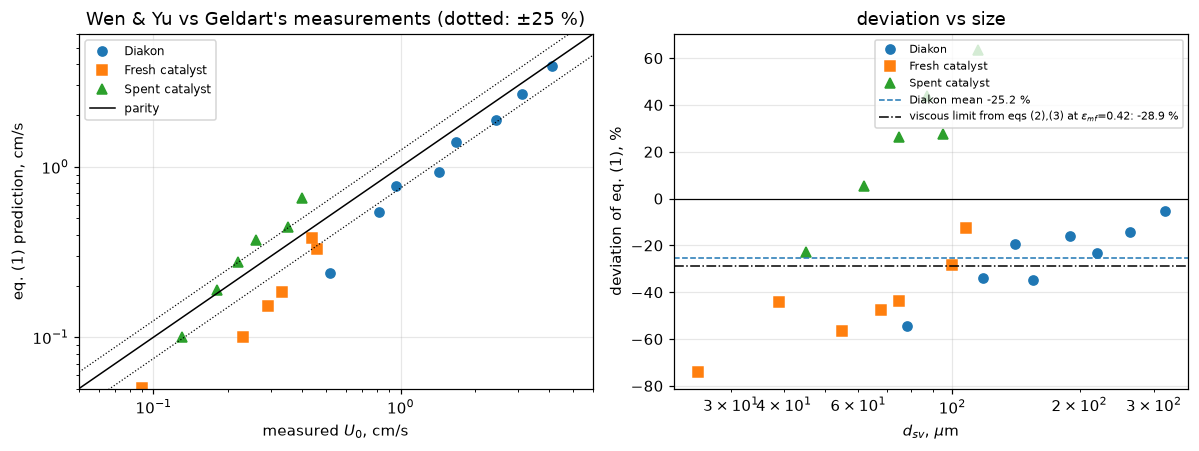

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
mk = {"Diakon": ("o", "tab:blue"), "Fresh catalyst": ("s", "tab:orange"),
      "Spent catalyst": ("^", "tab:green")}
for p, g in res.groupby("powder", sort=False):
    mrk, c = mk[p]
    ax[0].loglog(g.U_0, g.u_WenYu, mrk, color=c, label=p)
    ax[1].semilogx(g.d_sv_um, g.dev_WenYu_pct, mrk, color=c, label=p)
lim = [0.05, 6]
ax[0].plot(lim, lim, "k-", lw=1, label="parity")
for f_ in (0.75, 1.25):
    ax[0].plot(lim, [f_*x for x in lim], "k:", lw=0.8)
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("measured $U_0$, cm/s"); ax[0].set_ylabel("eq. (1) prediction, cm/s")
ax[0].set_title("Wen & Yu vs Geldart's measurements (dotted: $\\pm$25 %)")
ax[0].legend(fontsize=8)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].axhline(DIA["bias"], color="tab:blue", ls="--", lw=1,
              label=f"Diakon mean {DIA['bias']:+.1f} %")
ax[1].axhline(DEV_VISC_042, color="k", ls="-.", lw=1,
              label=f"viscous limit from eqs (2),(3) at $\\epsilon_{{mf}}$=0.42: {DEV_VISC_042:+.1f} %")
ax[1].set_xlabel("$d_{sv}$, $\\mu$m"); ax[1].set_ylabel("deviation of eq. (1), %")
ax[1].set_title("deviation vs size"); ax[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

In [19]:
display(Markdown(fill(r"""The three powders behave differently and the split is worth reading before the
summary. The two catalysts are the rows carrying both the unknown sphericity and
the approximate density. The fresh catalyst is underpredicted by both correlations (bias
@@fb@@ % for Wen and Yu, @@fd@@ % for Davies and Richardson); the spent catalyst has measured
velocities so low for its stated $\rho_s \simeq 1.5$ that *both* overpredict it (@@sb@@ % and @@sd@@ %), Davies
and Richardson worse than Wen and Yu. That is a property of those rows, not a result about either
correlation, and it is why the headline below is the Diakon subset.

**The eight spherical rows are the ones worth reading in detail.** Diakon is the
only powder here that Geldart calls spherical, so it is the only one on which his
$d_{sv}$ can be identified with Wen and Yu's $d_p$ at all. Whether that
identification is *exact* depends on taking six words of prose at face value, and
Check 4 shows the headline number is a strong function of exactly that.

**Two of the five parts below are identities, not evidence, and both are labelled
as such.** This matters more than it sounds:

- Part **(b)** inverts each measured $U_0$ for the voidage the exact balance
  would need. That is a **change of variables on the same measurement**, not an
  independent quantity: the gap between the voidage eq. (2) forces on a sphere and the inverted
  $\epsilon$ *is* the deviation re-expressed, by construction, for any data
  whatsoever. Both sides also share $\phi_s = 1$ and Ergun's $k_1 = 150$, which
  are needed to turn a constant into a voidage at all. The one thing in (b) that
  could genuinely have come out otherwise is whether the demanded voidage lands
  somewhere physically sensible, and part **(c)** shows that this is exactly the
  question the data do *not* settle.
- Part **(d)**, the viscous constant each row demands, is the same statement a
  third time: $u_{mf}$ is inversely proportional to that constant in this regime,
  so $\overline{K}/1650 - 1$ *is* the bias. Read (d) for its spread and its size
  trend, not for its centre.

**Part (c) is the contrary evidence, and it is in the page's own dataset.**
Geldart prints a bed voidage. Run the unapproximated balance at *that* voidage
and it is not a good reference at all: it is far high. The page reports this
rather than resolving it.
""", fb=f"{FRESH['bias']:+.0f}", fd=f"{FRESH['dr_bias']:+.0f}", sb=f"{SPENT['bias']:+.0f}", sd=f"{SPENT['dr_bias']:+.0f}")))
assert FRESH["bias"] < 0 and FRESH["dr_bias"] < 0 and SPENT["bias"] > 0 and SPENT["dr_bias"] > SPENT["bias"]

The three powders behave differently and the split is worth reading before the
summary. The two catalysts are the rows carrying both the unknown sphericity and
the approximate density. The fresh catalyst is underpredicted by both correlations (bias
-44 % for Wen and Yu, -26 % for Davies and Richardson); the spent catalyst has measured
velocities so low for its stated $\rho_s \simeq 1.5$ that *both* overpredict it (+24 % and +64 %), Davies
and Richardson worse than Wen and Yu. That is a property of those rows, not a result about either
correlation, and it is why the headline below is the Diakon subset.

**The eight spherical rows are the ones worth reading in detail.** Diakon is the
only powder here that Geldart calls spherical, so it is the only one on which his
$d_{sv}$ can be identified with Wen and Yu's $d_p$ at all. Whether that
identification is *exact* depends on taking six words of prose at face value, and
Check 4 shows the headline number is a strong function of exactly that.

**Two of the five parts below are identities, not evidence, and both are labelled
as such.** This matters more than it sounds:

- Part **(b)** inverts each measured $U_0$ for the voidage the exact balance
  would need. That is a **change of variables on the same measurement**, not an
  independent quantity: the gap between the voidage eq. (2) forces on a sphere and the inverted
  $\epsilon$ *is* the deviation re-expressed, by construction, for any data
  whatsoever. Both sides also share $\phi_s = 1$ and Ergun's $k_1 = 150$, which
  are needed to turn a constant into a voidage at all. The one thing in (b) that
  could genuinely have come out otherwise is whether the demanded voidage lands
  somewhere physically sensible, and part **(c)** shows that this is exactly the
  question the data do *not* settle.
- Part **(d)**, the viscous constant each row demands, is the same statement a
  third time: $u_{mf}$ is inversely proportional to that constant in this regime,
  so $\overline{K}/1650 - 1$ *is* the bias. Read (d) for its spread and its size
  trend, not for its centre.

**Part (c) is the contrary evidence, and it is in the page's own dataset.**
Geldart prints a bed voidage. Run the unapproximated balance at *that* voidage
and it is not a good reference at all: it is far high. The page reports this
rather than resolving it.


In [20]:
dia_rows = res[dia]
d_d, drho_d, U_d, Ga_d = AUX["d_d"], AUX["drho_d"], AUX["U_d"], AUX["Ga_d"]
DEV_DIA_ROW = dev[dia]
print("(a0) eq. (1) row by row on the eight Diakon cuts: it is low on EVERY row,")
print("     but NOT by the same amount; the spread is a factor of ten.")
assert np.all(DEV_DIA_ROW < 0)
print("    " + "  ".join(f"{v:+.1f}" for v in DEV_DIA_ROW) + "  %")
print(f"    mean {DEV_DIA_ROW.mean():+.1f} %, range {DEV_DIA_ROW.min():+.1f} % to "
      f"{DEV_DIA_ROW.max():+.1f} %, rms {MEAS['wenyu_rms_diakon_pct']:.1f} %; "
      f"ratio of the largest to the smallest {DEV_DIA_ROW.min()/DEV_DIA_ROW.max():.1f}")
print("    No row is near the mean. 'low by 25 % on every row' would be wrong;")
print("    'low on every row, by 25 % on average' is what the data say. Part of")
print("    that spread is the systematic size trend quantified in (d) below.")

print("\n(a) the exact Ergun balance, phi_s = 1, at voidages Wen & Yu themselves print")
ERGUN_AT_QUOTED = {}
for eps in (0.386, 0.40, 0.42):
    u = u_mf_from_re(ergun_re_mf(Ga_d, 1.0, eps), d_d)
    dv = 100 * (u - U_d) / U_d
    ERGUN_AT_QUOTED[eps] = float(dv.mean())
    print(f"    eps_mf = {eps:.3f}:  bias {dv.mean():+7.2f} %   MAD {np.abs(dv).mean():6.2f} %")
print(f"    eq. (1) itself      :  bias {DIA['bias']:+7.2f} %   MAD {DIA['mad']:6.2f} %")
print("  The unapproximated equation BRACKETS zero bias across the voidages Wen & Yu")
print("  print for spheres, and eq. (1) sits outside that bracket on the low side,")
print(f"  consistent with the eps_mf = {EPS_FROM_2:.3f} that eq. (2) forces at phi_s = 1.")
print(f"  But the bracket is WIDE and it is not centred: at 0.386 (Wen & Yu's own")
print(f"  ref. 21 average) the unapproximated balance is {ERGUN_AT_QUOTED[0.386]:+.2f} % biased, almost")
print(f"  as far off as eq. (1)'s {DIA['bias']:+.2f} %. Only the 0.42 end of the bracket makes")
print("  the Ergun equation look like a clean reference, and part (c) shows that the")
print("  one voidage Geldart himself reports does not support it at all.")

print("\n(b) invert each row for the eps_mf the exact balance needs (phi_s = 1; find_roots on "
      f"{EPS_FCC:.4f} to 1, the voidage of the densest equal-sphere packing up to an empty bed)"
      "\n    [A REPARAMETERISATION OF (a0), NOT AN INDEPENDENT MEASUREMENT: the gap")
print("     between eq. (2)'s sphere voidage and these numbers IS the deviation, by construction, and")
print("     both sides use the same phi_s = 1, the same d_sv/mu/g/drho and the same")
print("     Ergun k1 = 150. Its ONE falsifiable element is whether the demanded")
print("     voidage is physically sensible, which (c) puts in doubt.]")
eps_row = AUX["eps_row"]
for dd, e in zip(dia_rows.d_sv_um, eps_row):
    print(f"    d_sv = {dd:3.0f} um  ->  eps_mf = {e:.4f}")
EPS_MED = MEAS["inverted_eps_mf_median_diakon"]
assert 0.386 <= EPS_MED <= 0.42 and eps_row.min() > EPS_FROM_2   # the wording below rests on this
print(f"    median {EPS_MED:.4f}, mean {eps_row.mean():.4f}, "
      f"range {eps_row.min():.4f} - {eps_row.max():.4f}")
print(f"    Wen & Yu print 0.36-0.46 for spheres, averages 0.386 / 0.40 / 0.42.")
print(f"    Eqs. (2)+(3) together imply {EPS_EFF:.4f} at phi_s = {PHI_EFF:.3f}.")
print(f"    Eq. (2) alone at phi_s = 1 forces {EPS_FROM_2:.4f}.")
print(f"    -> the demanded voidage and the paper's own literature values sit in the")
print(f"       same band ({EPS_MED:.3f} vs 0.386-0.42), BOTH above the "
      f"{EPS_FROM_2:.3f} the correlation uses.")
print(f"       That agreement is the one non-trivial content of (b), and (c) is the")
print(f"       reason it cannot be called a closure between independent quantities.")

(a0) eq. (1) row by row on the eight Diakon cuts: it is low on EVERY row,
     but NOT by the same amount; the spread is a factor of ten.
    -54.5  -34.0  -19.5  -34.8  -16.2  -23.2  -14.1  -5.5  %
    mean -25.2 %, range -54.5 % to -5.5 %, rms 29.0 %; ratio of the largest to the smallest 10.0
    No row is near the mean. 'low by 25 % on every row' would be wrong;
    'low on every row, by 25 % on average' is what the data say. Part of
    that spread is the systematic size trend quantified in (d) below.

(a) the exact Ergun balance, phi_s = 1, at voidages Wen & Yu themselves print
    eps_mf = 0.386:  bias  -22.95 %   MAD  22.95 %
    eps_mf = 0.400:  bias  -12.34 %   MAD  15.06 %
    eps_mf = 0.420:  bias   +4.82 %   MAD  17.71 %
    eq. (1) itself      :  bias  -25.21 %   MAD  25.21 %
  The unapproximated equation BRACKETS zero bias across the voidages Wen & Yu
  print for spheres, and eq. (1) sits outside that bracket on the low side,
  consistent with the eps_mf = 0.383 that eq. 

In [21]:
print("\n(c) CONTRARY EVIDENCE, from Geldart's own table: the voidage HE reports")
print("    Geldart prints eps_MB (bed voidage at minimum bubbling) and H_MB/H_0")
print("    (bed height at minimum bubbling over settled height) for every row, so")
print("    the settled voidage follows from a volume balance on the solids:")
print("        eps_0 = 1 - (1 - eps_MB) H_MB/H_0")
print("    and on the two coarsest Diakon cuts NO INFERENCE IS NEEDED AT ALL:")
print("    Geldart prints U_MB = U_0 and H_MB/H_0 = 1.000, so minimum bubbling IS")
print("    minimum fluidisation and the bed is still at its settled height. There")
print("    eps_mf = eps_MB = eps_0 exactly, as printed.")
eps_MB_d, H_d, eps_0_d = AUX["eps_MB"], AUX["H"], AUX["eps_0"]
dev_at_MB, dev_at_e0 = AUX["dev_MB"], AUX["dev_e0"]
NO_INFER = (np.abs(H_d - 1.0) <= 1e-5) & (np.abs(dia_rows.U_MB.to_numpy() / U_d - 1.0) <= 1e-5)
assert NO_INFER.sum() == NOINF["geldart_reported_eps_MB_no_inference_rows"]
print(f"\n{'d_sv':>6s} {'U_0':>6s} {'U_MB':>6s} {'H/H0':>6s} {'eps_MB':>7s} {'eps_0':>7s} "
      f"{'eps_inv':>8s} | {'eq.(1)':>8s} {'Ergun@eps_MB':>13s} {'Ergun@eps_0':>12s}")
for i in range(len(d_d)):
    tag = "  <- U_MB = U_0, H/H0 = 1.000: eps_mf = eps_MB, no inference" if NO_INFER[i] else ""
    print(f"{dia_rows.d_sv_um.iloc[i]:6.0f} {U_d[i]:6.2f} {dia_rows.U_MB.iloc[i]:6.2f} {H_d[i]:6.3f} "
          f"{eps_MB_d[i]:7.3f} {eps_0_d[i]:7.4f} {eps_row[i]:8.4f} | "
          f"{DEV_DIA_ROW[i]:+7.1f}% {dev_at_MB[i]:+12.1f}% {dev_at_e0[i]:+11.1f}%{tag}")
BIAS_AT_MB = MEAS["exact_ergun_bias_diakon_at_reported_eps_MB_pct"]
BIAS_AT_E0 = MEAS["exact_ergun_bias_diakon_at_settled_eps_0_pct"]
print(f"\n    mean bias, eight Diakon rows:")
print(f"      eq. (1)                                  {DIA['bias']:+8.2f} %")
print(f"      exact Ergun at Geldart's PRINTED eps_MB  {BIAS_AT_MB:+8.2f} %")
print(f"      exact Ergun at the settled eps_0         {BIAS_AT_E0:+8.2f} %")
print(f"      exact Ergun at the INVERTED eps of (b)     {0.0:+8.2f} %   (exact by construction)")
i_ni = np.flatnonzero(NO_INFER)
print(f"\n    On the {len(i_ni)} rows where nothing is inferred, the 'unapproximated balance'")
print(f"    is {' and '.join(f'{dev_at_MB[i]:+.1f} %' for i in i_ni)} at eps_mf = "
      f"{eps_MB_d[i_ni][0]:.3f}, against eq. (1)'s "
      f"{' and '.join(f'{DEV_DIA_ROW[i]:+.1f} %' for i in i_ni)}.")
assert np.all(dev_at_MB[i_ni] > np.abs(DEV_DIA_ROW[i_ni]))
print("    THE EXACT ERGUN BALANCE IS WORSE THERE THAN THE CORRELATION IT IS BEING")
print("    USED TO JUDGE, in the opposite direction.")
print("\n    Sphericity cannot rescue this. Expressed in d_sv, the exact Ergun u_mf is")
print("    EXACTLY phi_s-independent: the phi's cancel between d_p = d_sv/phi_s,")
print("    N_Ga, N_Re and both Ergun groups. Demonstrated, not asserted:")


def u_mf_exact_from_dsv(d_sv_cm, drho_, eps, phi, phi_in_inertial_group=True):
    """Exact Ergun u_mf written in the SURFACE/VOLUME diameter Geldart prints.

    ``phi_in_inertial_group=False`` injects a defect: the sphericity left out of the
    inertial group, so that it no longer cancels."""
    dp = np.asarray(d_sv_cm, float) / phi
    Ga = dp**3 * RHOF_CGS * np.asarray(drho_, float) * G_CGS / MU_CGS**2
    a = K2_ERGUN / ((phi if phi_in_inertial_group else 1.0) * eps**3)
    b = K1_ERGUN * (1.0 - eps) / (phi**2 * eps**3)
    Re = (np.sqrt(b**2 + 4.0 * a * Ga) - b) / (2.0 * a)
    return u_mf_from_re(Re, dp)


def phi_independence(**kw):
    """Largest relative change of the exact u_mf at Geldart's eps_MB when phi_s goes from 1 to 0.9 and 0.6."""
    base = u_mf_exact_from_dsv(d_d, drho_d, eps_MB_d, 1.0, **kw)
    return float(max(np.max(np.abs(u_mf_exact_from_dsv(d_d, drho_d, eps_MB_d, p, **kw) / base - 1.0))
                     for p in (0.90, 0.60)))


for phi_try in (1.0, 0.90, 0.60):
    uu = u_mf_exact_from_dsv(d_d, drho_d, eps_MB_d, phi_try)
    print(f"      phi_s = {phi_try:.2f}:  u_mf at Geldart's eps_MB = "
          + ", ".join(f"{v:.4f}" for v in uu[:3]) + ", ...  cm/s"
          + ("   <- identical" if phi_try != 1.0 else ""))
PHI_SPREAD = phi_independence()
claims.bound("ergun_phi_s_independence_spread", PHI_SPREAD, max=1e-10, basis="identity",
             note="phi_s cancels analytically; what remains is round-off")
print(f"      max relative spread over those three phi_s: below 1e-10 (here {PHI_SPREAD:.1e}), round-off")
print("      The REFERENCE is phi_s-free; eq. (1) is not (Check 4). So sphericity")
print("      can move the correlation but cannot move this contradiction.")
print("\n    SO THE PAGE DOES NOT CLAIM THAT THE BIAS BELONGS TO EQS. (2) AND (3)")
print("    RATHER THAN TO THE ERGUN EQUATION. What the data support is narrower:")
print(f"    the voidage eq. (2) forces at phi_s = 1 ({EPS_FROM_2:.3f}) is below the band that")
print(f"    reproduces Geldart's U_0 through the Ergun balance (median {EPS_MED:.3f}), and")
print("    that shortfall accounts for the bias arithmetically. But Geldart's own")
print(f"    reported voidage runs {eps_MB_d.min():.3f}-{eps_MB_d.max():.3f} (median "
      f"{np.median(eps_MB_d):.3f}) and is {eps_MB_d[NO_INFER][0]:.3f} on the two")
print(f"    rows that need no inference; at THOSE voidages the same balance")
print(f"    overpredicts his U_0 by {BIAS_AT_MB:.0f} % on average. Three readings are open, and")
print("    nothing on this page chooses between them:")
print("      (i)  eq. (2)'s voidage is too low and the Ergun balance is right at the inverted voidage;")
print("      (ii) Geldart's U_0 sit systematically BELOW the Ergun balance at his own")
print("           reported voidage, i.e. the reference itself is biased on this bed;")
print("      (iii) Diakon is not perfectly spherical, which moves eq. (1) but not the")
print("           reference at all (see Check 4).")
print("    CAVEAT ON eps_MB AND H_MB/H_0: Geldart's section 4.2 gives a measurement")
print("    method for U_0 and U_MB only. A1.7's data sidecar records eps_MB and")
print("    H_MB/H_0 as REPORTED, method unstated. They are not called measurements")
print("    here either, but they are the only bed voidages either paper prints.")
print("\n    RECONCILIATION WITH A1.7, which computes the settled voidage and the Davies-Richardson ratio")
print("    from the same rows (relative gaps, same formulas in two codes):")
print(f"      eps_0 range over all {len(gd)} rows, here {np.min(1-(1-gd.eps_MB)*gd.H_MB_over_H_0):.6f} to "
      f"{np.max(1-(1-gd.eps_MB)*gd.H_MB_over_H_0):.6f} against A1.7's {_A17['eps0_inferred_min']:.6f} to "
      f"{_A17['eps0_inferred_max']:.6f}: gap below 1e-9 (here {claims['a17_eps0_range_gap']:.1e})")
_ratio = 1.0 / (DR_CONST * AUX["K_row"])
print(f"      eq. (3) constant over its printed one, Diakon rows, here {_ratio.min():.4f} to {_ratio.max():.4f} "
      f"against A1.7's {_A17['eq3_K0eff_ratio_min_diakon']:.4f} to {_A17['eq3_K0eff_ratio_max_diakon']:.4f}: "
      f"gap below 1e-9 (here {MEAS['a17_eq3_constant_ratio_gap']:.1e})")

print("\n(d) the viscous constant each Diakon row demands"
      "   [ITS CENTRE IS THE BIAS RESTATED - read it for the spread and the trend]")
K_row = AUX["K_row"]
K_WY = K1_ERGUN * G2_PRINT
K_DR = 1 / DR_CONST
print(f"    per row: {np.round(K_row, 0)}")
print(f"    median {np.median(K_row):.0f}, spread {K_row.min():.0f}-{K_row.max():.0f} "
      f"(factor {K_row.max()/K_row.min():.2f})")
print(f"    Wen & Yu:               k1 x eq.(2) = {K_WY:g}")
print(f"    Davies & Richardson:    1 / 8e-4     = {K_DR:g}")
rho_s_, p_s = MEAS["residual_size_rank_correlation"], MEAS["residual_size_rank_pvalue"]
print(f"\n    residual independence: Spearman rank correlation of the demanded constant")
print(f"    with particle size is rho = {rho_s_:+.3f} (p = {p_s:.3f}) over {len(d_d)} rows,")
print(f"    and the sequence above is not monotone: it falls {MEAS['demanded_constant_decreases']} times.")
print("    The residuals are NOT independent of size, so no standard error is quoted")
print("    on the refitted constant below and none should be inferred from the spread.")

print("\n(e) null baselines, on the same eight rows and the same deviation convention")
u_ref = d_d**2 * drho_d * G_CGS / (np.median(K_row) * MU_CGS)
nulls = [("constant u = mean of the measured column", np.full_like(U_d, U_d.mean())),
         ("constant u = median of the measured column", np.full_like(U_d, np.median(U_d))),
         ("one-parameter d^2 law, constant refit to these rows", u_ref),
         ("Davies & Richardson eq. (3), nothing fitted", AUX["u_dr"][dia]),
         ("Wen & Yu eq. (1), nothing fitted", AUX["u_wy"][dia])]
for name, u in nulls:
    dv = 100 * (u - U_d) / U_d
    print(f"    {name:52s} bias {dv.mean():+7.2f} %  MAD {np.abs(dv).mean():6.2f} %")
MAD_REFIT = MEAS["refit_one_parameter_mad_diakon_pct"]
print(f"\n    Reading: the two constant-velocity nulls are hopeless, so the d^2 scaling")
print(f"    is doing real work and a MAD in the teens is the floor here, not zero.")
print(f"    Eq. (1) carries {DIA['mad']:.1f} % MAD, all of it bias ({DIA['bias']:+.1f} %).")
print(f"    Refitting its single viscous constant to these very rows leaves {MAD_REFIT:.1f} %,")
print(f"    so {100-100*(DIA['mad']-MAD_REFIT)/DIA['mad']:.0f} % of eq. (1)'s error here survives ANY")
print("    one-parameter correction (part of it the size trend in (d)), and the rest")
print("    is what the approximation costs. Davies & Richardson, which is also a")
print(f"    one-parameter d^2 law but with a constant of {K_DR:g}, is already at that floor.")
EPS_EQUIV_DR = one_root(lambda e: K1_ERGUN * (1 - e) / e**3 - K_DR, EPS_FCC, 1.0, xtol=1e-12)
print(f"\n    AND D&R IS NOT INDEPENDENT CORROBORATION OF THE VOIDAGE EITHER. Its hidden")
print(f"    constant {K_DR:g} is k1 (1-eps)/eps^3 at eps = {EPS_EQUIV_DR:.3f}, essentially the "
      f"{EPS_MED:.3f}")
print(f"    the inversion in (b) demands. It agrees because it encodes the same voidage,")
print(f"    not because two independent routes met. That is why it is presented here as a")
print(f"    null baseline already at the one-parameter floor, and not as a second witness.")


(c) CONTRARY EVIDENCE, from Geldart's own table: the voidage HE reports
    Geldart prints eps_MB (bed voidage at minimum bubbling) and H_MB/H_0
    (bed height at minimum bubbling over settled height) for every row, so
    the settled voidage follows from a volume balance on the solids:
        eps_0 = 1 - (1 - eps_MB) H_MB/H_0
    and on the two coarsest Diakon cuts NO INFERENCE IS NEEDED AT ALL:
    Geldart prints U_MB = U_0 and H_MB/H_0 = 1.000, so minimum bubbling IS
    minimum fluidisation and the bed is still at its settled height. There
    eps_mf = eps_MB = eps_0 exactly, as printed.

  d_sv    U_0   U_MB   H/H0  eps_MB   eps_0  eps_inv |   eq.(1)  Ergun@eps_MB  Ergun@eps_0
    78   0.52   0.85  1.095   0.542  0.4985   0.4723 |   -54.5%        +74.0%       +23.7%
   118   0.82   1.17  1.065   0.496  0.4632   0.4285 |   -34.0%        +75.6%       +34.4%
   141   0.96   1.34  1.040   0.481  0.4602   0.4063 |   -19.5%        +89.5%       +59.7%
   155   1.43   1.60  1.012   0.4

### Check 4: could the measured comparison have failed?

The comparison above is a chain of unit conversions on someone else's table, and
a chain of unit conversions is exactly the thing that produces a confident wrong
number. Each row below breaks one link and re-reads the Diakon bias; every claim of
Check 3 is re-computed from the defective inputs and the rows it fails are recorded.

**One of those links is not a unit conversion but an assumption, and it is the
one the headline rides on: $\phi_s = 1$.** Geldart prints no numerical sphericity
for Diakon; $\phi_s = 1$ is read off six words of his prose. Equation (1) is
built on the volume-equivalent $d_p$ and Geldart tabulates $d_{sv} = \phi_s d_p$,
so the prediction scales as $(d_{sv}/\phi_s)^2$ in this regime, while the
reference it is scored against is exactly $\phi_s$-free (part (c) above). All of
the sphericity risk therefore lands on the reported number, and none of it on the
reference. The break table below carries $\phi_s$ rows, and the cell solves
(`find_roots` on the paper's own $\phi_s$ range) for the $\phi_s$ that would account
for the whole bias.

In [22]:
DEFECTS = [
    ("d_sv taken in mm instead of um",                dict(d_to_cm=0.1)),
    ("mu = 1.8e-5 Pa s instead of 1.8e-4 poise",      dict(mu=1.8e-5)),
    ("g = 9.81 (SI) instead of 981 cm/s2",            dict(g=9.81)),
    ("rho_f dropped from the density difference",     dict(rho_f_in_drho=False)),
    ("rho_f = 1.2e-4 (a decade wrong)",               dict(rho_f=1.2e-4)),
    ("measured U_MB used in place of U_0",            dict(u_col="U_MB")),
    ("U_0 column shifted down by one row",            dict(u_shift=1)),
    ("the blank U_0 row kept instead of dropped",     dict(drop_blank=False)),
    ("eq. (1) replaced by exact Ergun, eps=0.42",     dict(wy_fn=lambda G: ergun_re_mf(G, 1.0, 0.42))),
    ("eq. (1) with C1 and C2 swapped in the root",    dict(wy_c=(C2_PRINT, C1_PRINT))),
    ("Davies-Richardson constant 8e-3, a decade high", dict(dr_const=8e-3)),
    # --- the assumption, not a unit: d_p = d_sv/phi_s -----------------------
    ("phi_s = 0.95 instead of 1 (d_p = d_sv/phi_s)",  dict(phi_s=0.95)),
    ("phi_s = 0.90 instead of 1 (d_p = d_sv/phi_s)",  dict(phi_s=0.90)),
]
base_bias = MEAS["wenyu_bias_diakon_pct"]
print(f"{'injected defect':46s} {'Diakon bias':>12s} {'moves by':>10s}   claims failed")
DEF_RUNS = {}
for name, kw in DEFECTS:
    got, _ = measured(strict=False, **kw)
    DEF_RUNS[name] = got
    caught = [brk(name, k, v) for k, v in got.items() if k in claims.metrics]
    b = got["wenyu_bias_diakon_pct"]
    print(f"{name:46s} {b:+11.2f} % {b-base_bias:+9.2f}   {sum(caught):2d} of {len(caught)}")

# --- how much sphericity would it take to erase the headline entirely? ------
PHI_ZERO_BIAS = MEAS["phi_s_that_erases_diakon_bias"]
dia_bias_at = AUX["diakon_bias"]
print("\nSPHERICITY SENSITIVITY: the assumption the headline rides on.")
print("Eq. (1) uses the volume-equivalent d_p; Geldart tabulates d_sv = phi_s d_p.")
print("In this regime u_mf ~ (d_sv/phi_s)^2, so the PREDICTION moves with phi_s while")
print("the reference of part (c) does not move at all.")
print(f"\n{'assumed phi_s':>15s} {'Diakon bias':>13s}")
for p in (1.00, 0.95, 0.90, PHI_ZERO_BIAS):
    tag = "   <- the page's assumption, read off six words of prose" if p == 1.00 else (
        "   <- the whole headline is gone" if p == PHI_ZERO_BIAS else "")
    print(f"{p:15.3f} {dia_bias_at(p):+12.2f} %{tag}")
PHI_REMOVED_095 = 100 * (1 - MEAS["diakon_bias_at_phi_s_095_pct"] / base_bias)
print(f"\nphi_s = {PHI_ZERO_BIAS:.3f} would account for 100 % of the Diakon bias, a departure from a sphere of "
      f"{100*(1-PHI_ZERO_BIAS):.1f} %. A perfectly")
print(f"ordinary 0.95 for sieved suspension-polymerised beads removes {PHI_REMOVED_095:.0f} % of it.")
print("So the measured verdict is a JOINT test of the voidage approximation AND of")
print("Diakon's sphericity, and the page cannot separate them: Geldart prints no")
print("numerical phi_s, only the phrase 'having spherical particles'.")
print("Under the plausible readings the headline is:")
for p, word in ((1.00, "spherical exactly"), (0.95, "very nearly spherical"), (0.90, "roughly spherical")):
    print(f"   phi_s = {p:.2f} ({word:22s}) -> eq. (1) low by {abs(dia_bias_at(p)):.1f} % on average")

def rho_shifts(rho_gas=RHOF_CGS):
    """Change (points) of the Diakon bias when the gas density ``rho_gas`` is dropped from the density
    difference, and when it is wrong by a decade everywhere it is used (N_Ga, N_Re, the density difference)."""
    b0 = measured(rho_f=rho_gas, strict=False)[0]["wenyu_bias_diakon_pct"]
    drop = measured(rho_f=rho_gas, rho_f_in_drho=False, strict=False)[0]["wenyu_bias_diakon_pct"]
    decade = measured(rho_f=0.1 * rho_gas, strict=False)[0]["wenyu_bias_diakon_pct"]
    return dict(rho_f_dropped_bias_shift_pts=drop - b0, rho_f_decade_bias_shift_pts=decade - b0)


RHO = rho_shifts()
for name, v in RHO.items():
    claims.value(name, v)
brk_all("gas density 0.1 g/cm3 (a dense gas) in the sensitivity run", rho_shifts(0.1))
rho_move, rho_decade = RHO["rho_f_dropped_bias_shift_pts"], RHO["rho_f_decade_bias_shift_pts"]
print("\nWHAT THIS CHECK CANNOT DO, measured rather than asserted:")
print(f"  * rho_f. Dropping it from the density difference moves the bias by {rho_move:+.2f} points,")
print(f"    a decade error by {rho_decade:+.2f}, and rho_f is not printed by either paper. The page makes no claim about it.")
print("    (It does NOT cancel from N_Ga and N_Re separately, only from the answer, in")
print("     the viscous limit, where u_mf = d^2 (rho_s-rho_f) g / (1650 mu).)")
print("  * The turbulent constant. See the resolving-power cell below.")
print(f"  * phi_s. It is not measured anywhere, and anything from {PHI_ZERO_BIAS:.3f} to 1 is")
print("    consistent with what Geldart writes. The headline is quoted at phi_s = 1")
print("    with that sensitivity stated, not with an error bar it does not have.")

injected defect                                 Diakon bias   moves by   claims failed
d_sv taken in mm instead of um                   +58802.01 % +58827.23   25 of 31
mu = 1.8e-5 Pa s instead of 1.8e-4 poise           +500.64 %   +525.86   25 of 31
g = 9.81 (SI) instead of 981 cm/s2                  -99.25 %    -74.04   25 of 31
rho_f dropped from the density difference           -25.14 %     +0.08    2 of 31
rho_f = 1.2e-4 (a decade wrong)                     -24.86 %     +0.35    7 of 31
measured U_MB used in place of U_0                  -34.41 %     -9.20   26 of 31
U_0 column shifted down by one row                   -0.10 %    +25.11   24 of 31
the blank U_0 row kept instead of dropped           -25.21 %     +0.00    6 of 31
eq. (1) replaced by exact Ergun, eps=0.42            +4.82 %    +30.03   17 of 31
eq. (1) with C1 and C2 swapped in the root       +53421.92 % +53447.14   17 of 31
Davies-Richardson constant 8e-3, a decade high      -25.21 %     +0.00    3 of 31
phi_s = 0.9

### What the measured test cannot resolve

Before quoting the agreement, the question `docs/agent-brief.md` insists on: is
the effect being tested larger than what the data can see? For half of equation
(1), the answer is no.

In [23]:
Re_meas_pred, Ga_all = AUX["Re"], AUX["Ga"]
assert Re_meas_pred.max() < 1.0      # every measured row is below (N_Re)_mf = 1, as the text says
inert_share = AUX["inert"]
i_big = int(np.argmax(inert_share))      # a data row: the one with the largest inertial share
print(f"(N_Re)_mf over Geldart's 21 rows: {Re_meas_pred.min():.2e} to {Re_meas_pred.max():.3f}")
print(f"Wen & Yu's Figure 4 spans (N_Re)_mf 0.001 to 4000 (journal page 611).")
print(f"\nContribution of the inertial term of eq. (1) on these rows: "
      f"{inert_share.min():.4f} % to {inert_share.max():.2f} %")
print(f"Largest row (a data row, the {i_big + 1}th of {len(inert_share)}): "
      f"{m_.powder.iloc[i_big]}, d_sv = {m_.d_sv_um.iloc[i_big]:.0f} um.")
print("\nSo this dataset tests 1/(k1 x eq.2) = 1/1650 and NOTHING ELSE. Setting the")
print("turbulent constant to any value at all changes the Diakon bias by:")


def inertial_shift(hold_viscous=True, factors=(0.25, 4.0)):
    """Largest change (points) of the Diakon bias when C2 is scaled by ``factors``; with
    ``hold_viscous`` C1 follows so that the viscous limit C2/(2 C1) is unchanged."""
    shifts = []
    for f in factors:
        c2 = C2_PRINT * f
        c1 = C1_PRINT * f if hold_viscous else C1_PRINT
        shifts.append(measured(wy_c=(c1, c2), strict=False)[0]["wenyu_bias_diakon_pct"] - base_bias)
    return shifts


SHIFTS = inertial_shift()
for f, sh in zip((0.25, 4.0), SHIFTS):
    print(f"   C2 x {f:.2f} at fixed viscous limit -> bias {base_bias + sh:+.3f} % ({sh:+.3f} points)")
claims.value("inertial_constant_scaled_max_shift_pts", max(abs(s) for s in SHIFTS))
brk("C2 scaled with C1 held, so the viscous limit moves too", "inertial_constant_scaled_max_shift_pts",
    max(abs(s) for s in inertial_shift(hold_viscous=False)))
print("\nThat is the page's largest blind spot and it is structural: no group A powder")
print("can probe the inertial term. Result 3 shows how large the approximation's error is there for")
print("the voidages the paper quotes, and nothing on this page tests any of it against a measurement.")

print("\n--- and are these rows inside the ranges eqs. (2) and (3) are stated to cover? ---")
D_MAX_IN, DDC_MAX = 1.97, 0.25            # journal page 611
COLUMN_CM = 5.0                           # Geldart section 4.2
print(f"stated d_p range      : {D_MIN_IN} to {D_MAX_IN} in. "
      f"= {D_MIN_IN*25400:.1f} um to {D_MAX_IN*25.4:.0f} mm")
print(f"Geldart's rows        : {m_.d_sv_um.min():.0f} to {m_.d_sv_um.max():.0f} um "
      f"= {d_in.min():.5f} to {d_in.max():.5f} in.")
print(f"stated d_p/D range    : {DDC_MIN} to {DDC_MAX}")
print(f"Geldart's rows (5 cm) : {ddc.min():.6f} to {ddc.max():.5f}")
N_OUT_D, N_OUT_R = claims["rows_below_stated_dp_range"], claims["rows_below_stated_dp_over_D_range"]
print(f"\n{N_OUT_D} of the {len(m_)} rows fall below the stated d_p bound, "
      f"{N_OUT_R} below the stated d_p/D bound:")
for i in range(len(m_)):
    flags = ("d_p" if d_in[i] < D_MIN_IN else "   ") + " " + ("d_p/D" if ddc[i] < DDC_MIN else "")
    if flags.strip():
        print(f"   {m_.powder.iloc[i]:16s} d_sv = {m_.d_sv_um.iloc[i]:3.0f} um   below: {flags}")
dia_um = m_.d_sv_um[dia]
assert not any(d_in[dia] < D_MIN_IN) and not any(ddc[dia] < DDC_MIN)
print(f"\nAll of them are catalyst rows; every Diakon cut is inside both ranges "
      f"({dia_um.min():.0f}-{dia_um.max():.0f} um). Those bounds are the extremes of the")
print("population eqs. (2) and (3) were fitted over, not a proof of failure outside")
print("them, but the fresh-catalyst rows are the worst on the page and they are")
print("also the ones at and below the fitted edge.")

# break rows for the data-only counts and gaps
for row, kw in [("stated d_p bound mis-read as 0.02 in.", dict(dmin_in=0.02)),
                ("column diameter read as 2.5 cm (a radius)", dict(column_cm=2.5))]:
    di, dc = range_counts(**{k: v for k, v in kw.items() if k == "column_cm"})
    dmin = kw.get("dmin_in", D_MIN_IN)
    brk_all(row, dict(rows_below_stated_dp_range=int(np.sum(di < dmin)),
                      rows_below_stated_dp_over_D_range=int(np.sum(dc < DDC_MIN))))
brk_all("no-inference test loosened to 1 % in H and 5 % in U", no_inference(h_tol=1e-2, u_tol=5e-2))
brk("settled voidage taken as eps_MB (height ratio ignored)", "a17_eps0_range_gap", eps0_gap(ignore_height=True))
brk("phi_s left out of the inertial group of the exact balance", "ergun_phi_s_independence_spread",
    phi_independence(phi_in_inertial_group=False))

(N_Re)_mf over Geldart's 21 rows: 3.43e-04 to 0.824
Wen & Yu's Figure 4 spans (N_Re)_mf 0.001 to 4000 (journal page 611).

Contribution of the inertial term of eq. (1) on these rows: 0.0005 % to 1.22 %
Largest row (a data row, the 8th of 21): Diakon, d_sv = 318 um.

So this dataset tests 1/(k1 x eq.2) = 1/1650 and NOTHING ELSE. Setting the
turbulent constant to any value at all changes the Diakon bias by:
   C2 x 0.25 at fixed viscous limit -> bias -26.102 % (-0.888 points)
   C2 x 4.00 at fixed viscous limit -> bias -24.979 % (+0.235 points)

That is the page's largest blind spot and it is structural: no group A powder
can probe the inertial term. Result 3 shows how large the approximation's error is there for
the voidages the paper quotes, and nothing on this page tests any of it against a measurement.

--- and are these rows inside the ranges eqs. (2) and (3) are stated to cover? ---
stated d_p range      : 0.002 to 1.97 in. = 50.8 um to 50 mm
Geldart's rows        : 25 to 318 um = 

True

In [24]:
display(Markdown(fill(r"""### Blind spots: claims this page does **not** make

Each of these is a thing a reader might reasonably assume the page has shown. It
has not.

1. **That equation (1) is 25 % low in general, or 25 % low on any particular
   row.** It is low on *every* one of eight spherical cuts of one plastic powder
   at $(N_{Re})_{mf} < 1$, by @@bias@@ % *on average*, and the per-row spread is a
   factor of ten (printed at the top of Check 3). No row is near the mean. The
   paper's own claim over 284 points spanning $(N_{Re})_{mf}$ from 0.001 to 4000
   is $\pm$ 25 % *average* deviation, and this page neither confirms nor
   contradicts it there. @@nout@@ of the 21 rows, all catalyst, none Diakon, are
   also finer than the smallest particle equations (2) and (3) were fitted over,
   which the last cell of Check 3 locates and which is worth knowing before
   reading the fresh-catalyst column.
2. **That Ergun's constants are right.** Check 1 identifies which friction-law
   constants Wen and Yu used; it says nothing about whether they are correct, and
   only the products $k_1\times 11$ and $k_2\times 14$ are identifiable at all.
   A compensating error in $k_1$ and in equation (2) is invisible to every check
   here.
3. **That the shape-factor claim holds.** Equation (1)'s selling point is that it
   needs no $\phi_s$. Testing that needs non-spherical powders with a *known*
   $\phi_s$, and neither paper on this page provides one: Geldart's two
   catalysts have no printed sphericity, which is exactly why substituting
   $d_{sv}$ for $d_p$ on those 13 rows is recorded as a definitional caveat and
   why the headline is the Diakon subset.
4. **That $\phi_s = 1$ for Diakon, or that the headline is insensitive to it.**
   This is the same gap as (3) pointed at the *reported number* rather than at
   the correlation's claim, and it is the strongest single dependence on the
   page. $\phi_s = 1$ rests on six words of Geldart's prose and no printed value.
   Because equation (1) is built on $d_p = d_{sv}/\phi_s$ and the reference of
   Check 3(c) is exactly $\phi_s$-free, the headline moves with $\phi_s^{-2}$ and
   the reference does not move at all: Check 4 prints the bias at
   $\phi_s = 0.95$ and $0.90$ and solves for the $\phi_s$ that would account for
   *all* of it. A perfectly ordinary departure from perfect sphericity removes a
   large fraction of the headline, and a @@dep@@ % departure removes the whole of
   it. The measured verdict is a joint test of the voidage approximation and of
   Diakon's sphericity, and nothing here separates the two.
5. **That the unapproximated Ergun balance is the right reference, or that the
   bias belongs to equations (2) and (3) rather than to it.** Check 3(c) is the
   page's own contrary evidence: at the bed voidage Geldart himself reports, the
   *unapproximated* balance overpredicts his $U_0$ badly, worse than equation (1)
   underpredicts it, and on two rows the voidage needs no inference at all
   because he prints $U_{MB} = U_0$ and $H_{MB}/H_0 = 1.000$. The inverted
   voidage of Check 3(b) explains the bias arithmetically; Geldart's reported
   voidage does not; and nothing on this page settles which is right.
6. **That $\rho_f$ matters.** It is not printed by either paper. The break table
   measures its influence and it is small (@@rho@@ points on the bias when it is dropped from the density
   difference); the page therefore asserts nothing about it rather than claiming
   insensitivity as a result.
7. **That the size trend in the Diakon residuals is understood.** The viscous
   constant each cut demands rises with size (Spearman $\rho = @@rs@@$), *rises*, not
   monotonically: the sequence printed in (d) falls @@nd@@ times. The page
   reports the rank correlation and its p-value and stops there. Sphericity,
   cohesion at the fine end, wall effects at
   $d_p/D = 318\,\mu\text{m}/5\,\text{cm}$ and the voidage of a sieved cut all
   vary along that axis and nothing here separates them.
8. **That anything in Wen and Yu's Figure 4 has been checked.** It was not
   digitised. The 284 points are quoted only through the statistics the authors
   computed from them.
9. **That the derivation is the authors'.** It is reconstructed. The companion
   paper that contains their own derivation was not consulted, and the evidence
   that the reconstruction is theirs is the recovery of 33.7 and 0.0408: strong,
   but circumstantial.
""", bias=f"{abs(DIA['bias']):.1f}", nout=int(N_OUT_D), dep=f"{100*(1-PHI_ZERO_BIAS):.0f}",
    rho=f"{rho_move:+.2f}", rs=f"{rho_s_:+.3f}", nd=MEAS["demanded_constant_decreases"])))

### Blind spots: claims this page does **not** make

Each of these is a thing a reader might reasonably assume the page has shown. It
has not.

1. **That equation (1) is 25 % low in general, or 25 % low on any particular
   row.** It is low on *every* one of eight spherical cuts of one plastic powder
   at $(N_{Re})_{mf} < 1$, by 25.2 % *on average*, and the per-row spread is a
   factor of ten (printed at the top of Check 3). No row is near the mean. The
   paper's own claim over 284 points spanning $(N_{Re})_{mf}$ from 0.001 to 4000
   is $\pm$ 25 % *average* deviation, and this page neither confirms nor
   contradicts it there. 3 of the 21 rows, all catalyst, none Diakon, are
   also finer than the smallest particle equations (2) and (3) were fitted over,
   which the last cell of Check 3 locates and which is worth knowing before
   reading the fresh-catalyst column.
2. **That Ergun's constants are right.** Check 1 identifies which friction-law
   constants Wen and Yu used; it says nothing about whether they are correct, and
   only the products $k_1\times 11$ and $k_2\times 14$ are identifiable at all.
   A compensating error in $k_1$ and in equation (2) is invisible to every check
   here.
3. **That the shape-factor claim holds.** Equation (1)'s selling point is that it
   needs no $\phi_s$. Testing that needs non-spherical powders with a *known*
   $\phi_s$, and neither paper on this page provides one: Geldart's two
   catalysts have no printed sphericity, which is exactly why substituting
   $d_{sv}$ for $d_p$ on those 13 rows is recorded as a definitional caveat and
   why the headline is the Diakon subset.
4. **That $\phi_s = 1$ for Diakon, or that the headline is insensitive to it.**
   This is the same gap as (3) pointed at the *reported number* rather than at
   the correlation's claim, and it is the strongest single dependence on the
   page. $\phi_s = 1$ rests on six words of Geldart's prose and no printed value.
   Because equation (1) is built on $d_p = d_{sv}/\phi_s$ and the reference of
   Check 3(c) is exactly $\phi_s$-free, the headline moves with $\phi_s^{-2}$ and
   the reference does not move at all: Check 4 prints the bias at
   $\phi_s = 0.95$ and $0.90$ and solves for the $\phi_s$ that would account for
   *all* of it. A perfectly ordinary departure from perfect sphericity removes a
   large fraction of the headline, and a 14 % departure removes the whole of
   it. The measured verdict is a joint test of the voidage approximation and of
   Diakon's sphericity, and nothing here separates the two.
5. **That the unapproximated Ergun balance is the right reference, or that the
   bias belongs to equations (2) and (3) rather than to it.** Check 3(c) is the
   page's own contrary evidence: at the bed voidage Geldart himself reports, the
   *unapproximated* balance overpredicts his $U_0$ badly, worse than equation (1)
   underpredicts it, and on two rows the voidage needs no inference at all
   because he prints $U_{MB} = U_0$ and $H_{MB}/H_0 = 1.000$. The inverted
   voidage of Check 3(b) explains the bias arithmetically; Geldart's reported
   voidage does not; and nothing on this page settles which is right.
6. **That $\rho_f$ matters.** It is not printed by either paper. The break table
   measures its influence and it is small (+0.08 points on the bias when it is dropped from the density
   difference); the page therefore asserts nothing about it rather than claiming
   insensitivity as a result.
7. **That the size trend in the Diakon residuals is understood.** The viscous
   constant each cut demands rises with size (Spearman $\rho = +0.833$), *rises*, not
   monotonically: the sequence printed in (d) falls 2 times. The page
   reports the rank correlation and its p-value and stops there. Sphericity,
   cohesion at the fine end, wall effects at
   $d_p/D = 318\,\mu\text{m}/5\,\text{cm}$ and the voidage of a sieved cut all
   vary along that axis and nothing here separates them.
8. **That anything in Wen and Yu's Figure 4 has been checked.** It was not
   digitised. The 284 points are quoted only through the statistics the authors
   computed from them.
9. **That the derivation is the authors'.** It is reconstructed. The companion
   paper that contains their own derivation was not consulted, and the evidence
   that the reconstruction is theirs is the recovery of 33.7 and 0.0408: strong,
   but circumstantial.


In [25]:
# The break table, after every claim is registered: one line per injected defect, with the claims it fails.
by_row = {}
for r_, m_name, clean_, broken_, caught_ in BREAK:
    by_row.setdefault(r_, []).append((m_name, caught_))
print(f"{'injected defect':<76} {'claims failed':>13} of {'reported':>8}")
for r_, ms in by_row.items():
    print(f"{r_[:76]:<76} {sum(c_ for _, c_ in ms):13d} of {len(ms):8d}")
_caught = {k for _, k, _, _, c_ in BREAK if c_}
_open = sorted(k for k in claims.metrics if k not in _caught and not claims.metrics[k].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"open: {', '.join(_open) or 'none'}")

injected defect                                                              claims failed of reported
eqs. (2) and (3) swapped                                                                11 of       11
eq. (2) mis-read as 1.1                                                                  7 of       11
eq. (3) mis-read as 4                                                                   10 of       11
Kozeny-Carman k1 = 180 instead of 150                                                    2 of       11
Eisfeld-Schnitzlein infinite bed, 154 / 1.32                                             4 of       11
eq. (2) mis-read as 12                                                                   4 of       11
C1 and C2 swapped in eq. (1)                                                             4 of        4
Kozeny-Carman k1 = 180 in the reference balance                                          3 of        5
Eisfeld-Schnitzlein k2 (1.32) in the reference balance                   

In [26]:
display(Markdown(fill(r"""## What pymrm adds

**To the correlation itself, nothing, and this page does not pretend otherwise.**
Equation (1) is a closed-form root and no operator, grid or solver appears
anywhere above. What pymrm contributes is `pymrm.checks.find_roots`, and only that.
It does five root finds: the effective particle of Result 2
(and the count of roots of its quartic on $(0,1)$), the voidage eq. (2) forces on a
sphere, the voidage each Diakon row demands of the exact balance, the voidage at
which Davies and Richardson's constant sits, and the sphericity that erases the bias. Each scans
a physically possible range, refines every sign change and reports how many there
were, so a defect that leaves no root, or two, raises instead of returning a
number; the break tables rely on that. It adds no physics, and the rest of the page
is NumPy and SciPy.

What the reimplementation adds, none of it a solver, is four things.

**The derivation, made explicit and made falsifiable.** The communication states
that equation (1) came from the Ergun equation and prints the two approximations,
but the algebra between them is in a companion paper nobody here has. Doing it
recovers 33.7 and 0.0408 to a tenth of a per cent, and the break table shows
every alternative reading of its inputs (a swapped pair, a Kozeny-Carman
constant, the Eisfeld-Schnitzlein infinite-bed constants) moving the answer by
at least @@worst@@ %. That fixes, from the outside, which friction-law constants the
correlation encodes, which the paper does not say. The same table states the
limit: it cannot separate 150 from `A1.1`'s refitted @@k1r@@.

**The effective particle.** Equations (2) and (3) are usually quoted as two
independent conveniences. They are not independent: together they determine
$\phi_s$ and $\epsilon_{mf}$ uniquely, and the pair they determine is not a
sphere. Force $\phi_s = 1$ and they contradict each other by @@gap@@ % in
$\epsilon_{mf}$; the branch that survives into the viscous term is @@e2@@, which
is below the paper's own stated $\epsilon_{mf}$ floor. Anyone using equation (1)
on a fine spherical powder is using a correlation built around a packing looser
than any of the ones its authors cite, and this page is where that is computed
rather than asserted.

**The error budget, split, one limit at a time, and with the voidage it depends on.**
Against the equation it came from, the correlation's deviation is far larger than the
uncertainty in Ergun's own constants *in the viscous limit* at the $\epsilon_{mf} = 0.42$
Wen and Yu print for their own data, measured with `A1.1`'s refit of those constants
to Ergun's own figure: @@rv@@ times larger. In the turbulent limit the two are the same
size (@@rt@@ times). Quoting a single ratio hides that, and so does quoting a single
voidage: the voidage cost changes sign between the voidages the paper quotes, so
that at 0.385 and 0.386 the turbulent end is the worse one. A reader needs the
whole table of Result 3 in order to set a design margin, not one entry of it.

**A measurement the correlation never saw, and a contradiction inside it.** The
paper contains no data, only statistics computed from a figure. Geldart's Table 1
supplies 21 minimum fluidisation velocities from another laboratory seven years
later. Inverting the unapproximated balance row by row on the eight spherical
cuts asks what voidage would reproduce them; the answer sits in the same band as
the literature values Wen and Yu themselves quote for spheres and above the one
their correlation uses, and that shortfall accounts for the bias. **That
inversion is a reparameterisation of the bias, not an independent
corroboration**: it shares $\phi_s = 1$, the same sizes and gas properties and
Ergun's own $k_1$ with the thing it is compared to, and the gap *is* the
deviation by construction. Its one falsifiable element is whether the demanded
voidage is physically sensible, and there the same table supplies contrary
evidence the page reports rather than resolves: Geldart's own reported bed
voidage, needing no inference at all on the two coarsest cuts where he prints
$U_{MB} = U_0$ and $H_{MB}/H_0 = 1.000$, is *higher*, and at that voidage the
unapproximated balance overpredicts his velocities by more than equation (1)
underpredicts them. What this page adds is that both numbers are on the same
page, computed from the same table, with neither hidden.
""", worst=f"{WORST_ALT:.0f}", k1r=f"{K1_REFIT:.1f}", gap=f"{SPH['eps_mf_eq2_eq3_gap_pct']:.0f}",
    e2=f"{EPS_FROM_2:.3f}", rv=f"{RATIO_VISC:.0f}", rt=f"{RATIO_TURB:.2f}")))
assert WORST_ALT > 10 * BEST_READ and RATIO_VISC > 20 and 0.5 < RATIO_TURB < 2

## What pymrm adds

**To the correlation itself, nothing, and this page does not pretend otherwise.**
Equation (1) is a closed-form root and no operator, grid or solver appears
anywhere above. What pymrm contributes is `pymrm.checks.find_roots`, and only that.
It does five root finds: the effective particle of Result 2
(and the count of roots of its quartic on $(0,1)$), the voidage eq. (2) forces on a
sphere, the voidage each Diakon row demands of the exact balance, the voidage at
which Davies and Richardson's constant sits, and the sphericity that erases the bias. Each scans
a physically possible range, refines every sign change and reports how many there
were, so a defect that leaves no root, or two, raises instead of returning a
number; the break tables rely on that. It adds no physics, and the rest of the page
is NumPy and SciPy.

What the reimplementation adds, none of it a solver, is four things.

**The derivation, made explicit and made falsifiable.** The communication states
that equation (1) came from the Ergun equation and prints the two approximations,
but the algebra between them is in a companion paper nobody here has. Doing it
recovers 33.7 and 0.0408 to a tenth of a per cent, and the break table shows
every alternative reading of its inputs (a swapped pair, a Kozeny-Carman
constant, the Eisfeld-Schnitzlein infinite-bed constants) moving the answer by
at least 20 %. That fixes, from the outside, which friction-law constants the
correlation encodes, which the paper does not say. The same table states the
limit: it cannot separate 150 from `A1.1`'s refitted 151.9.

**The effective particle.** Equations (2) and (3) are usually quoted as two
independent conveniences. They are not independent: together they determine
$\phi_s$ and $\epsilon_{mf}$ uniquely, and the pair they determine is not a
sphere. Force $\phi_s = 1$ and they contradict each other by 8 % in
$\epsilon_{mf}$; the branch that survives into the viscous term is 0.383, which
is below the paper's own stated $\epsilon_{mf}$ floor. Anyone using equation (1)
on a fine spherical powder is using a correlation built around a packing looser
than any of the ones its authors cite, and this page is where that is computed
rather than asserted.

**The error budget, split, one limit at a time, and with the voidage it depends on.**
Against the equation it came from, the correlation's deviation is far larger than the
uncertainty in Ergun's own constants *in the viscous limit* at the $\epsilon_{mf} = 0.42$
Wen and Yu print for their own data, measured with `A1.1`'s refit of those constants
to Ergun's own figure: 23 times larger. In the turbulent limit the two are the same
size (1.17 times). Quoting a single ratio hides that, and so does quoting a single
voidage: the voidage cost changes sign between the voidages the paper quotes, so
that at 0.385 and 0.386 the turbulent end is the worse one. A reader needs the
whole table of Result 3 in order to set a design margin, not one entry of it.

**A measurement the correlation never saw, and a contradiction inside it.** The
paper contains no data, only statistics computed from a figure. Geldart's Table 1
supplies 21 minimum fluidisation velocities from another laboratory seven years
later. Inverting the unapproximated balance row by row on the eight spherical
cuts asks what voidage would reproduce them; the answer sits in the same band as
the literature values Wen and Yu themselves quote for spheres and above the one
their correlation uses, and that shortfall accounts for the bias. **That
inversion is a reparameterisation of the bias, not an independent
corroboration**: it shares $\phi_s = 1$, the same sizes and gas properties and
Ergun's own $k_1$ with the thing it is compared to, and the gap *is* the
deviation by construction. Its one falsifiable element is whether the demanded
voidage is physically sensible, and there the same table supplies contrary
evidence the page reports rather than resolves: Geldart's own reported bed
voidage, needing no inference at all on the two coarsest cuts where he prints
$U_{MB} = U_0$ and $H_{MB}/H_0 = 1.000$, is *higher*, and at that voidage the
unapproximated balance overpredicts his velocities by more than equation (1)
underpredicts them. What this page adds is that both numbers are on the same
page, computed from the same table, with neither hidden.


## Reuse

**Use equation (1) when** you need $u_{mf}$ from size, density and gas
properties alone, and you do not have $\epsilon_{mf}$ or $\phi_s$. That is most
of the time, and it is why the correlation won. `re_mf_wen_yu` is two lines.

In [27]:
U_VISC = lambda e: e**3 / (1.0 - e)        # u_mf of the exact balance in the viscous limit, up to a constant
SPREAD_U = U_VISC(0.46) / U_VISC(0.385)
display(Markdown(fill(r"""**Use `ergun_re_mf` instead when** you do have $\epsilon_{mf}$ *and* you know how
it was obtained, **and read Check 3(c) before you trust the result.** The
unapproximated balance is more faithful physics, but it is exquisitely sensitive
to the voidage you feed it, and on this page's own dataset the two available
voidages disagree by an amount that flips the verdict. At the voidage the eight
spherical cuts *demand*, it is unbiased by construction. At the voidage Geldart
*reports* for those same cuts, including two rows where no inference is needed,
it overpredicts his measured velocities by tens of per cent (@@bmb@@ % on average), worse in absolute
terms than equation (1) underpredicts them. A settled-bed height is exactly the
kind of number that produces the second case, not the first. So: `ergun_re_mf`
lets you use a measured voidage, but a measured voidage is not automatically the
right one, and $\epsilon_{mf}$ at the point of lifting is not the settled-bed
voidage unless the bed has not expanded. If you take one thing from this page
into a design, take the *sensitivity*: in the viscous limit equation (1) is
fixed and only $\epsilon_{mf}$ moves, and between 0.385 and 0.46 the
unapproximated balance's $u_{mf}$ changes by a factor of @@spread@@.

**Expect the error to be size-dependent, not uniform, and do not expect a
constant offset.** Where $(N_{Re})_{mf}$ is small compared with the printed constant 33.7 the correlation carries the
full error of equation (2); where it is large the square root has
halved the error of equation (3). Which of the two is the larger depends on the
voidage (Result 3): at 0.42 the viscous end, at 0.385 the turbulent one. Even within
the eight-row spherical subset here the per-row deviation spans a factor of ten and
rises systematically with size. Design margins should not be symmetric and should not
be a single percentage.

**And if your particles are only nearly spherical, that matters more than it
looks.** Equation (1) wants the volume-equivalent $d_p$; most tabulated sizes are
surface/volume or sieve diameters, and $d_{sv} = \phi_s d_p$. In the viscous
regime the prediction goes as $(d_{sv}/\phi_s)^2$, so a 10 % shortfall in
sphericity moves the reported bias on these eight rows by @@pts@@ points, larger than
almost anything else on the page. Check 4 measures exactly that, and the same
table gives the $\phi_s$ at which the whole bias disappears.

**And note where $u_{mf}$ goes next.** It is an input, not an output, for most of
section E: the excess gas $u_0 - u_{mf}$ drives the bubble phase in the two-phase
theory, so a 25 % error in $u_{mf}$ at $u_0 = 3u_{mf}$ is a 12.5 % error in the
bubbling gas flow and a larger one close to incipient conditions. Nothing here
propagates that through a bed model; it is arithmetic, stated so a reader knows
which way it points.

**Related pages.** [`A1.1`](../A1.1-ergun-pressure-drop/) is the friction law
this correlation is a root of, and supplies both the printed and the refitted
constants used above. [`A1.7`](../A1.7-geldart-classification/) supplies the
measured dataset and uses a *different* $u_{mf}$ expression (Davies and
Richardson's, via Geldart's eq. (3)) inside its group A/B boundary; the two are
compared row by row in Check 3. `A1.5` (Richardson-Zaki) takes the same bed past
incipient fluidisation, and `E2.1` and `E1.2` consume $u_{mf}$ as a parameter.

**Cite the sources, not this page:** Wen, C. Y. and Yu, Y. H., *A generalized
method for predicting the minimum fluidization velocity*, A.I.Ch.E. Journal
**12**(3) 610-612 (1966),
[doi:10.1002/aic.690120343](https://doi.org/10.1002/aic.690120343); the
derivation is in Wen, C. Y. and Yu, Y. H., *Chem. Eng. Progr. Symposium Series*
No. 62, **62** (1966), which was not consulted. Geldart, D., *Types of gas
fluidization*, Powder Technology **7**(5) 285-292 (1973),
[doi:10.1016/0032-5910(73)80037-3](https://doi.org/10.1016/0032-5910(73)80037-3).
Ergun, S., *Fluid flow through packed columns*, Chemical Engineering Progress
**48**(2) 89-94 (1952).
""", bmb=f"{BIAS_AT_MB:.0f}", spread=f"{SPREAD_U:.2f}",
    pts=f"{abs(MEAS['diakon_bias_at_phi_s_090_pct'] - base_bias):.0f}")))
assert 1.5 < SPREAD_U < 2.0 and BIAS_AT_MB > abs(DIA["bias"])

**Use `ergun_re_mf` instead when** you do have $\epsilon_{mf}$ *and* you know how
it was obtained, **and read Check 3(c) before you trust the result.** The
unapproximated balance is more faithful physics, but it is exquisitely sensitive
to the voidage you feed it, and on this page's own dataset the two available
voidages disagree by an amount that flips the verdict. At the voidage the eight
spherical cuts *demand*, it is unbiased by construction. At the voidage Geldart
*reports* for those same cuts, including two rows where no inference is needed,
it overpredicts his measured velocities by tens of per cent (58 % on average), worse in absolute
terms than equation (1) underpredicts them. A settled-bed height is exactly the
kind of number that produces the second case, not the first. So: `ergun_re_mf`
lets you use a measured voidage, but a measured voidage is not automatically the
right one, and $\epsilon_{mf}$ at the point of lifting is not the settled-bed
voidage unless the bed has not expanded. If you take one thing from this page
into a design, take the *sensitivity*: in the viscous limit equation (1) is
fixed and only $\epsilon_{mf}$ moves, and between 0.385 and 0.46 the
unapproximated balance's $u_{mf}$ changes by a factor of 1.94.

**Expect the error to be size-dependent, not uniform, and do not expect a
constant offset.** Where $(N_{Re})_{mf}$ is small compared with the printed constant 33.7 the correlation carries the
full error of equation (2); where it is large the square root has
halved the error of equation (3). Which of the two is the larger depends on the
voidage (Result 3): at 0.42 the viscous end, at 0.385 the turbulent one. Even within
the eight-row spherical subset here the per-row deviation spans a factor of ten and
rises systematically with size. Design margins should not be symmetric and should not
be a single percentage.

**And if your particles are only nearly spherical, that matters more than it
looks.** Equation (1) wants the volume-equivalent $d_p$; most tabulated sizes are
surface/volume or sieve diameters, and $d_{sv} = \phi_s d_p$. In the viscous
regime the prediction goes as $(d_{sv}/\phi_s)^2$, so a 10 % shortfall in
sphericity moves the reported bias on these eight rows by 17 points, larger than
almost anything else on the page. Check 4 measures exactly that, and the same
table gives the $\phi_s$ at which the whole bias disappears.

**And note where $u_{mf}$ goes next.** It is an input, not an output, for most of
section E: the excess gas $u_0 - u_{mf}$ drives the bubble phase in the two-phase
theory, so a 25 % error in $u_{mf}$ at $u_0 = 3u_{mf}$ is a 12.5 % error in the
bubbling gas flow and a larger one close to incipient conditions. Nothing here
propagates that through a bed model; it is arithmetic, stated so a reader knows
which way it points.

**Related pages.** [`A1.1`](../A1.1-ergun-pressure-drop/) is the friction law
this correlation is a root of, and supplies both the printed and the refitted
constants used above. [`A1.7`](../A1.7-geldart-classification/) supplies the
measured dataset and uses a *different* $u_{mf}$ expression (Davies and
Richardson's, via Geldart's eq. (3)) inside its group A/B boundary; the two are
compared row by row in Check 3. `A1.5` (Richardson-Zaki) takes the same bed past
incipient fluidisation, and `E2.1` and `E1.2` consume $u_{mf}$ as a parameter.

**Cite the sources, not this page:** Wen, C. Y. and Yu, Y. H., *A generalized
method for predicting the minimum fluidization velocity*, A.I.Ch.E. Journal
**12**(3) 610-612 (1966),
[doi:10.1002/aic.690120343](https://doi.org/10.1002/aic.690120343); the
derivation is in Wen, C. Y. and Yu, Y. H., *Chem. Eng. Progr. Symposium Series*
No. 62, **62** (1966), which was not consulted. Geldart, D., *Types of gas
fluidization*, Powder Technology **7**(5) 285-292 (1973),
[doi:10.1016/0032-5910(73)80037-3](https://doi.org/10.1016/0032-5910(73)80037-3).
Ergun, S., *Fluid flow through packed columns*, Chemical Engineering Progress
**48**(2) 89-94 (1952).


In [28]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A1.6:
  C1_recovered                                   = 33.673           value  rtol 0.05
  C2_recovered                                   = 0.040816         value  rtol 0.05
  C1_deviation_pct                               = -0.078726        value  rtol 0.05
  C2_deviation_pct                               = 0.040016         value  rtol 0.05
  quartic_roots_in_unit_interval                 = 2                exact  exact
  implied_eps_mf                                 = 0.47442          value  rtol 0.05
  implied_phi_s                                  = 0.66891          value  rtol 0.05
  second_root_phi_s                              = 0.088718         value  rtol 0.05
  eps_mf_forced_by_eq2_at_sphere                 = 0.38283          value  rtol 0.05
  eps_mf_forced_by_eq3_at_sphere                 = 0.41491          value  rtol 0.05
  eps_mf_eq2_eq3_gap_pct                         = 8.3809           value  rtol 0.05
  dev_vs_exact_ergun_viscous_eps042_pct          = -